# How much movement capacity survives a turn?

Our defensive-front scouting question is whether repeatable recovery after direction change predicts rookie pressure performance beyond conventional traits and tracked sprint capacity. We distinguish better measurement, individual stress-curve identification and NFL prediction. These are separate achievements. The same 74-player cohort and the already-inspected 2025 class make this an adaptive exploratory program.

We draw on broader machinery concretely: DynaComp's unchanged rational bounds transport declared measurement boxes, its finite compiler preserves specified quantized readouts, and its rational algebra detects unobserved response directions. WIND-style target ambiguity motivates sensitivity/rank audits. PerfectPower-style finite planning evaluates complete small populations of additional demand trials. These calculations do not certify physiology or unseen NFL performance.


In [1]:
import os,sys,json,hashlib,tempfile,contextlib
from pathlib import Path
from IPython.display import display,Image
DATA=Path(os.environ.get('BDB_DATA_ROOT','/kaggle/input/nfl-big-data-bowl-2027')).resolve()
if not (DATA/'players.csv').exists():
    options=list(Path('/kaggle/input').rglob('players.csv')) if Path('/kaggle/input').exists() else []
    if len(options)!=1:raise FileNotFoundError('Attach official input or set BDB_DATA_ROOT')
    DATA=options[0].parent
WORK=Path(os.environ.get('BDB_WORK_ROOT',tempfile.mkdtemp(prefix='bdb_stress_'))).resolve();WORK.mkdir(exist_ok=True)
os.chdir(WORK);sys.path.insert(0,str(WORK))
MODULES={'analysis.py': '"""Combine-to-game research. No competition data are bundled or fabricated."""\nfrom pathlib import Path\nimport json, hashlib, argparse, platform\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor\n\nSEED=20271006\nBASE=[\'combine_height\',\'combine_weight\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\']\nCONTEXT=[\'cushion\',\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\']\nCATS=[\'route_ran\',\'team_coverage_man_zone\',\'offense_formation\',\'in_motion_at_ball_snap\']\nMOTION=[\'entry_speed\',\'speed_retention\',\'exit_gain\',\'braking_impulse\',\'turn_angle\',\'curvature_energy\',\'jerk_rms\',\'signature_area\']\nCUT_ROUTES={\'OUT\',\'SLANT\',\'POST\',\'CORNER\',\'HITCH\'}\n\ndef movement(g,window=7):\n    """Largest interior heading change; fixed +/-0.5s event window, yards/seconds."""\n    g=g.sort_values(\'time\').copy()\n    t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    if len(t)<21 or np.any(np.diff(t)<=0): raise ValueError(\'short or duplicate/nonmonotone trajectory\')\n    dt=np.diff(t)\n    if not np.allclose(dt,.1,atol=.015): raise ValueError(\'irregular sampling; do not interpolate missing cuts\')\n    p=g[[\'x\',\'y\']].to_numpy(float)\n    if not np.isfinite(p).all(): raise ValueError(\'nonfinite coordinates\')\n    p=savgol_filter(p,window,3,axis=0)\n    v=np.gradient(p,.1,axis=0);a=np.gradient(v,.1,axis=0)\n    speed=np.linalg.norm(v,axis=1)\n    theta=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    k=np.arange(5,len(p)-5)\n    score=np.abs(theta[k+3]-theta[k-3]);score[(speed[k-3]<1)|(speed[k+3]<1)]=0\n    if score.max()<np.deg2rad(25): raise ValueError(\'no qualifying turn\')\n    c=int(k[np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-10))[0]]);sl=slice(c-5,c+6)\n    turn=theta[c+3]-theta[c-3]\n    tangent=v[c-3]/speed[c-3];normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-5])@np.stack([tangent,normal],axis=1)\n    q[:,1]*=1 if turn>=0 else -1\n    # Antisymmetric level-two path signature, equal to signed area with closing chord.\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])\n    sp=speed[sl];at=np.gradient(sp,.1)\n    omega=np.gradient(theta,.1)[sl];curv=omega/np.maximum(sp,1)\n    out=dict(entry_speed=float(np.mean(sp[:3])),speed_retention=float(sp.min()/np.mean(sp[:3])),\n      exit_gain=float(np.mean(sp[-3:])-sp.min()),braking_impulse=float(np.trapezoid(np.maximum(-at,0),dx=.1)),\n      turn_angle=float(abs(turn)),curvature_energy=float(np.trapezoid(curv**2*sp,dx=.1)),\n      jerk_rms=float(np.sqrt(np.mean(np.gradient(a[sl],.1,axis=0)**2))),signature_area=float(area))\n    diag={\'t\':np.arange(-5,6)*.1,\'q\':q,\'speed\':sp,\'tangential_acceleration\':at,\'cut_index\':c}\n    return out,diag\n\ndef inventory(root):\n    """Stream all CSVs; retain observed counts/schema/hash, never treat descriptions as measured counts."""\n    rows=[]\n    for p in sorted(Path(root).glob(\'*.csv\')):\n        count=0;ids=set();years=set();cols=None\n        for c in pd.read_csv(p,chunksize=200000):\n            count+=len(c);cols=list(c.columns)\n            if \'nfl_id\' in c: ids.update(c.nfl_id.dropna().astype(int))\n            for key in (\'season\',\'draft_year\'):\n                if key in c:years.update(c[key].dropna().astype(int))\n        h=hashlib.sha256()\n        with p.open(\'rb\') as f:\n            for b in iter(lambda:f.read(8*1024*1024),b\'\'): h.update(b)\n        rows.append(dict(file=p.name,rows=count,unique_players=len(ids),years=sorted(years),columns=cols,sha256=h.hexdigest()))\n    return rows\n\ndef prepare(root,out):\n    root,out=Path(root),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(root/\'players.csv\');combine=pd.read_csv(root/\'combine_results.csv\');games=pd.read_csv(root/\'games.csv\')\n    for d,key in [(players,[\'nfl_id\']),(combine,[\'nfl_id\',\'draft_year\']),(games,[\'game_id\'])]:\n        if d.duplicated(key).any():raise ValueError(\'duplicate metadata join key\')\n    ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\']);pieces=[]\n    drill_counts={}\n    for c in pd.read_csv(root/\'combine_tracking.csv\',chunksize=200000):\n        c=c[c.nfl_id.isin(ids)&c.entity_type.eq(\'PLAYER\')&c.drill_type.eq(\'SKILL_DRILLS_WR\')]\n        pieces.append(c)\n        for name,n in c.drill_name.value_counts().items():drill_counts[name]=drill_counts.get(name,0)+int(n)\n    track=pd.concat(pieces,ignore_index=True);features=[];rejects=[]\n    for keys,g in track.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:\n            f,_=movement(g);features.append(dict(nfl_id=keys[0],draft_year=keys[1],event_id=keys[2],drill_name=g.drill_name.iloc[0],**f))\n        except ValueError as e:rejects.append(dict(event_id=keys[2],reason=str(e)))\n    f=pd.DataFrame(features)\n    if f.empty:raise ValueError(\'no qualifying WR turns; inspect drill availability before changing protocol\')\n    f.to_csv(out/\'attempt_features.csv\',index=False)\n    # Choose one homologous drill using Combine availability only, before NFL outcomes.\n    availability=f.groupby([\'drill_name\',\'draft_year\']).nfl_id.nunique().unstack(fill_value=0).reindex(columns=[2023,2024,2025],fill_value=0)\n    minimum=availability.min(axis=1);eligible=minimum[minimum>=5]\n    if eligible.empty:raise ValueError(\'no qualifying drill shared by >=5 WRs in every class; inspect availability\')\n    selected=sorted(eligible.index,key=lambda k:(-eligible[k],k))[0]\n    f=f[f.drill_name.eq(selected)]\n    agg=f.groupby([\'nfl_id\',\'draft_year\'])[MOTION].median().reset_index()\n    pp=pd.read_csv(root/\'player_play.csv\')\n    if pp.duplicated([\'game_id\',\'play_id\',\'nfl_id\']).any():raise ValueError(\'duplicate player-play key\')\n    pp=pp.merge(games[[\'game_id\',\'season\',\'season_type\']],on=\'game_id\',validate=\'many_to_one\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    d=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(CUT_ROUTES)&pp.play_nullified_by_penalty.eq(\'N\')].copy()\n    d=d[np.isfinite(d.separation_at_pass_forward)&(d.separation_at_pass_forward>=0)]\n    d=d.merge(combine,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(agg,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    # Each player must have >=20 measured routes. Threshold is frozen before labels are inspected.\n    n=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(n[n>=20].index)]\n    audit={\'status\':\'actual_data_prepared\',\'draft_class_players\':d.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\n      \'draft_class_routes\':d.groupby(\'draft_year\').size().to_dict(),\'wr_roster_players\':len(ids),\'qualifying_attempts\':len(f),\n      \'selected_drill\':selected,\'drill_player_availability\':availability.to_dict(),\'excluded_attempts\':rejects,\'drill_frame_counts\':drill_counts,\'target_only_fraction\':float(d.target.mean()) if len(d) else None,\n      \'game_tracking_use\':\'Primary outcome uses official separation; game trajectory replication remains secondary and unrun.\'}\n    temp=out/\'private_analysis_rows.csv.tmp\';d.to_csv(temp,index=False);temp.replace(out/\'private_analysis_rows.csv\');\n    if len(pd.read_csv(out/\'private_analysis_rows.csv\'))!=len(d):raise ValueError(\'analysis CSV roundtrip row mismatch\')\n    d.to_pickle(out/\'private_analysis_rows.pkl\');(out/\'population_audit.json\').write_text(json.dumps(audit,indent=2))\n    return d,f,audit\n\ndef model(d,nums,kind,alpha=10):\n    numeric=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n    cats=Pipeline([(\'impute\',SimpleImputer(strategy=\'most_frequent\')),(\'onehot\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))])\n    pre=ColumnTransformer([(\'numeric\',numeric,nums),(\'category\',cats,CATS)])\n    reg=Ridge(alpha=alpha) if kind==\'ridge\' else RandomForestRegressor(n_estimators=200,min_samples_leaf=20,max_depth=6,max_features=.8,random_state=SEED,n_jobs=2)\n    return Pipeline([(\'pre\',pre),(\'reg\',reg)])\n\ndef weights(d):return 1/d.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy()\ndef score(d,p):return float(np.average((d.separation_at_pass_forward.to_numpy()-p)**2,weights=weights(d)))\n\ndef compare(d,out):\n    """Player-disjoint, rookie-season-disjoint validation and locked 2025 test."""\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);d=d.copy()\n    if not (d.season==d.draft_year).all():raise ValueError(\'rookie seasons required\')\n    for col in MOTION:\n        d[col+\'_mass\']=d[col]*d.combine_weight/200\n        d[col+\'_man\']=d[col]*d.team_coverage_man_zone.eq(\'MAN_COVERAGE\').astype(int)\n    families={\'conventional\':BASE+CONTEXT,\'tracking\':BASE+CONTEXT+MOTION,\n      \'physical_context_interactions\':BASE+CONTEXT+MOTION+[c+s for c in MOTION for s in (\'_mass\',\'_man\')],\n      \'scouting_reference\':BASE+CONTEXT+[\'ngs_college_production_score\']}\n    a,b,t=[d[d.draft_year.eq(y)] for y in (2023,2024,2025)]\n    if min(x.nfl_id.nunique() for x in (a,b,t))<10:raise ValueError(\'fewer than ten WRs in a class; insufficient locked-cohort study\')\n    assert not(set(a.nfl_id)&set(b.nfl_id) or set(a.nfl_id)&set(t.nfl_id) or set(b.nfl_id)&set(t.nfl_id))\n    dev=pd.concat([a,b]);results=[];pred={};selections={}\n    for kind in (\'ridge\',\'forest\'):\n      for family,nums in families.items():\n        options=(1,10,100) if kind==\'ridge\' else (10,)\n        vals=[]\n        for alpha in options:\n            m=model(a,nums,kind,alpha);m.fit(a,a.separation_at_pass_forward,reg__sample_weight=weights(a));vals.append((score(b,m.predict(b)),alpha))\n        _,alpha=min(vals);selections[kind+\'_\'+family]={\'alpha\':alpha,\'validation_mse\':min(vals)[0]}\n        m=model(dev,nums,kind,alpha);m.fit(dev,dev.separation_at_pass_forward,reg__sample_weight=weights(dev));p=m.predict(t)\n        name=kind+\'_\'+family;pred[name]=p\n        results.append({\'model\':name,\'test_player_balanced_mse\':score(t,p),\'test_rmse_yards\':score(t,p)**.5,\'validation_mse\':min(vals)[0]})\n    # Primary contrast is ridge tracking vs ridge conventional. Others exploratory.\n    losses=pd.DataFrame({\'nfl_id\':t.nfl_id,\'baseline\':(t.separation_at_pass_forward-pred[\'ridge_conventional\'])**2,\'tracking\':(t.separation_at_pass_forward-pred[\'ridge_tracking\'])**2}).groupby(\'nfl_id\').mean()\n    delta=(losses.baseline-losses.tracking).to_numpy();rng=np.random.default_rng(SEED)\n    boots=np.mean(rng.choice(delta,(5000,len(delta)),replace=True),axis=1)\n    report={\'status\':\'actual_data_completed\',\'primary_delta_mse_yards_squared\':float(delta.mean()),\'player_bootstrap_ci95\':np.quantile(boots,[.025,.975]).tolist(),\n      \'test_players\':len(delta),\'test_routes\':len(t),\'results\':results,\'selection\':selections,\n      \'interpretation\':\'positive delta favors motion; CI crossing zero is inconclusive; cohort-generalization requires more years\',\n      \'selection_warning\':\'Exploratory models cannot replace the preregistered primary contrast after observing test labels.\'}\n    pd.DataFrame(results).to_csv(out/\'model_comparisons.csv\',index=False)\n    (out/\'experiment_results.json\').write_text(json.dumps(report,indent=2))\n    pp=t[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in pred.items():pp[k]=v\n    pp.to_csv(out/\'private_test_predictions.csv\',index=False)\n    return report\n\ndef plot_motion(diag,path,label):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'text.color\':\'#e6edf6\',\'axes.labelcolor\':\'#c2cfde\',\'xtick.color\':\'#8aa0b6\',\'ytick.color\':\'#8aa0b6\',\'axes.edgecolor\':\'#304359\',\'axes.facecolor\':\'#102236\',\'figure.facecolor\':\'#071421\'})\n    fig,ax=plt.subplots(1,3,figsize=(16,5),layout=\'constrained\');q=diag[\'q\'];t=diag[\'t\'];s=diag[\'speed\'];a=diag[\'tangential_acceleration\']\n    sc=ax[0].scatter(q[:,0],q[:,1],c=s,cmap=\'plasma\',s=80,zorder=3);ax[0].plot(q[:,0],q[:,1],color=\'#39dbbd\',alpha=.8);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Along entry direction · yards\',ylabel=\'Across entry direction · yards\',title=\'THE SHAPE OF THE CUT\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\',shrink=.7)\n    ax[1].plot(t,s,lw=3,color=\'#39dbbd\');ax[1].axvline(0,color=\'#efb455\',ls=\':\');ax[1].set(xlabel=\'Seconds from largest turn\',ylabel=\'Speed · yd/s\',title=\'BRAKE → TURN → RECOVER\')\n    ax[2].plot(s,a,lw=2,color=\'#efb455\');ax[2].scatter(s,a,c=t,cmap=\'cool\',s=40);ax[2].axhline(0,color=\'#304359\');ax[2].set(xlabel=\'Speed · yd/s\',ylabel=\'Tangential acceleration · yd/s²\',title=\'MOVEMENT PHASE PORTRAIT\')\n    for z in ax:z.grid(alpha=.12)\n    fig.suptitle(label,fontsize=17,fontweight=\'bold\');fig.savefig(path,dpi=150);plt.close(fig)\n\ndef run(root,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    (out/\'inventory.json\').write_text(json.dumps(inventory(root),indent=2))\n    d,f,audit=prepare(root,out);report=compare(d,out)\n    # Selected example by sorted ID, independent of outcomes. Read only WR tracking rows.\n    chosen=f.sort_values([\'nfl_id\',\'event_id\']).iloc[0];parts=[]\n    for c in pd.read_csv(Path(root)/\'combine_tracking.csv\',chunksize=200000):parts.append(c[c.event_id.eq(chosen.event_id)&c.entity_type.eq(\'PLAYER\')])\n    g=pd.concat(parts);_,diag=movement(g);plot_motion(diag,out/\'actual_combine_geometry.png\',\'Observed Combine trajectory · selected without NFL outcomes\')\n    (out/\'actual_combine_geometry.html\').write_text(motion_html(diag,\'Observed Combine attempt · selected independently of NFL outcomes\'))\n    return report\n\n\ndef game_transfer(root,d,out):\n    """Secondary descriptive mechanics replication; game motion never a prospect predictor."""\n    out=Path(out);pieces=[];ids=set(d.nfl_id)\n    keys=d[[\'game_id\',\'play_id\',\'nfl_id\']].drop_duplicates()\n    for year in (2023,2024,2025):\n        p=Path(root)/f\'game_tracking_{year}.csv\';parts=[]\n        for c in pd.read_csv(p,chunksize=200000):\n            c=c[c.nfl_id.isin(ids)].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],how=\'inner\',validate=\'many_to_one\');parts.append(c)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\']):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if snap.empty or release.empty:continue\n            g=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:\n                f,_=movement(g);pieces.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            except ValueError:continue\n    pd.DataFrame(pieces).to_csv(out/\'private_game_motion.csv\',index=False)\n    return {\'status\':\'descriptive_only\',\'qualifying_game_turns\':len(pieces),\'note\':\'No 22-player coverage reconstruction. Game movement is outcome-side diagnostic, never a pre-draft predictor.\'}\n\ndef motion_html(diag,label):\n    """Offline SVG animation of measured samples, not a generated football replay."""\n    import html\n    data=json.dumps({k:diag[k].tolist() for k in (\'t\',\'q\',\'speed\',\'tangential_acceleration\')})\n    template=\'\'\'<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Inside the cut</title><style>\nbody{background:#071421;color:#e6edf6;font:17px system-ui;margin:0;padding:4vw}main{max-width:1000px;margin:auto}.tag{color:#39dbbd;font-size:12px;letter-spacing:2px}h1{font-size:clamp(28px,5vw,52px)}.layout{display:grid;grid-template-columns:2fr 1fr;gap:24px}svg{background:#102236;width:100%;border-radius:20px}button{background:#39dbbd;color:#071421;border:0;border-radius:9px;padding:12px 22px;font-weight:700}input{width:100%;accent-color:#39dbbd}small{color:#9cafc3}strong{font-size:40px;display:block}.metric{margin:22px 0}@media(max-width:650px){.layout{grid-template-columns:1fr}} </style>\n<main><div class="tag">MOVEMENT LAB · FRAME BY FRAME</div><h1>Inside the cut.</h1><p>LABEL</p><div class="layout"><svg id="field" viewBox="0 0 600 400" role="img" aria-label="Canonical trajectory in yards"><g id="grid"></g><path id="path" fill="none" stroke="#39dbbd" stroke-width="3"/><g id="samples"></g><circle id="player" r="12" fill="#efb455" stroke="#071421" stroke-width="4"/><text x="22" y="380" fill="#9cafc3" font-size="14">Canonical entry frame · yards</text></svg><aside><div class="metric">Time from detected turn<strong id="time"></strong><small>seconds</small></div><div class="metric">Speed<strong id="speed"></strong><small>yards / second</small></div><div class="metric">Braking / reacceleration<strong id="acc"></strong><small>yards / second²</small></div></aside></div><p><button id="play">Play movement</button> <small>Eleven observed samples; interpolation animates the marker only.</small></p><input id="frame" type="range" min="0" max="10" step=".01" value="0" aria-label="Inspect tracking moment"><p><small>The line is the sampled path. Color indicates speed. A positive acceleration value means the athlete is regaining speed. The dot does not represent a defender or a missing NFL player.</small></p></main>\n<script>const D=DATA;const ns=\'http://www.w3.org/2000/svg\';const xs=D.q.map(p=>p[0]),ys=D.q.map(p=>p[1]);let xmin=Math.min(...xs),xmax=Math.max(...xs),ymin=Math.min(...ys),ymax=Math.max(...ys);const scale=Math.min(500/Math.max(xmax-xmin,.2),280/Math.max(ymax-ymin,.2));const P=D.q.map(p=>[50+(p[0]-xmin)*scale,330-(p[1]-ymin)*scale]);function node(tag,attrs,parent){let e=document.createElementNS(ns,tag);for(let k in attrs)e.setAttribute(k,attrs[k]);parent.appendChild(e);return e}for(let x=Math.floor(xmin);x<=xmax;x++){const z=50+(x-xmin)*scale;node(\'line\',{x1:z,y1:20,x2:z,y2:350,stroke:\'#233c51\'},document.querySelector(\'#grid\'));const t=node(\'text\',{x:z,y:365,fill:\'#9cafc3\',\'font-size\':12},document.querySelector(\'#grid\'));t.textContent=x;}document.querySelector(\'#path\').setAttribute(\'d\',P.map((p,i)=>(i?\'L\':\'M\')+p.join(\',\')).join(\' \'));let low=Math.min(...D.speed),high=Math.max(...D.speed);P.forEach((p,i)=>node(\'circle\',{cx:p[0],cy:p[1],r:5,fill:`hsl(${180-140*(D.speed[i]-low)/Math.max(high-low,.01)} 75% 60%)`},document.querySelector(\'#samples\')));let f=document.querySelector(\'#frame\'),playing=false,last=0;function show(){let z=+f.value,i=Math.min(9,Math.floor(z)),a=z-i;let p=P[i].map((v,k)=>v+(P[i+1][k]-v)*a);document.querySelector(\'#player\').setAttribute(\'cx\',p[0]);document.querySelector(\'#player\').setAttribute(\'cy\',p[1]);for(let [id,key] of [[\'time\',\'t\'],[\'speed\',\'speed\'],[\'acc\',\'tangential_acceleration\']])document.querySelector(\'#\'+id).textContent=(D[key][i]+(D[key][i+1]-D[key][i])*a).toFixed(2)}f.oninput=()=>{playing=false;document.querySelector(\'#play\').textContent=\'Play movement\';show()};document.querySelector(\'#play\').onclick=()=>{playing=!playing;if(+f.value>=10)f.value=0;document.querySelector(\'#play\').textContent=playing?\'Pause\':\'Play movement\';last=performance.now()};function tick(now){if(playing){f.value=Math.min(10,+f.value+(now-last)/300);show();if(+f.value>=10){playing=false;document.querySelector(\'#play\').textContent=\'Replay movement\'}}last=now;requestAnimationFrame(tick)}show();requestAnimationFrame(tick);</script>\'\'\'\n    return template.replace(\'LABEL\',html.escape(label)).replace(\'DATA\',data)\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',required=True);ap.add_argument(\'--out\',default=\'private_results\');args=ap.parse_args();print(json.dumps(run(args.data,args.out),indent=2))\n', 'repo_predict.py': '"""Prospect-balanced compression and development-only model selection.\n\n2025 was already inspected before this push; its results are exploratory.\n"""\nfrom pathlib import Path\nimport json,time\nimport numpy as np,pandas as pd\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nfrom sklearn.model_selection import StratifiedGroupKFold\nimport analysis as A\n\nPHYS=A.BASE+[\'hand_size\',\'arm_length\',\'wing_span\',\'bench_reps\',\'ngs_athleticism_score\',\'ngs_college_production_score\',\'ngs_final_score\']\nNUM=A.CONTEXT+[\'quarter\']\nCAT=A.CATS+[\'team_coverage_type\',\'receiver_alignment\',\'team_abbr\',\'defense_team\']\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':1,\'k\':4},{\'reg\':\'ridge\',\'alpha\':10,\'k\':4},{\'reg\':\'ridge\',\'alpha\':100,\'k\':8},{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':8}]\n\nclass ProspectEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,motion=(),k=4):self.motion=motion;self.k=k\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_player_ids_=set(players.nfl_id)\n        self.phys=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.phys.fit(players[PHYS])\n        self.num=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.num.fit(x[NUM])\n        self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);self.cat.fit(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))\n        if self.motion:\n            m=players[list(self.motion)].to_numpy(float);self.lo=np.nanquantile(m,.01,axis=0);self.hi=np.nanquantile(m,.99,axis=0)\n            self.lo=np.nan_to_num(self.lo);self.hi=np.nan_to_num(self.hi)\n            self.mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);m=self.mi.fit_transform(np.clip(m,self.lo,self.hi));self.ms=StandardScaler();m=self.ms.fit_transform(m)\n            self.pca=PCA(n_components=min(self.k,len(players)-1,m.shape[1]),svd_solver=\'full\');self.pca.fit(m)\n        return self\n    def transform(self,x):\n        blocks=[self.phys.transform(x[PHYS]),self.num.transform(x[NUM]),self.cat.transform(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))]\n        if self.motion:\n            m=np.clip(x[list(self.motion)].to_numpy(float),self.lo,self.hi);blocks.append(self.pca.transform(self.ms.transform(self.mi.transform(m))))\n        return np.column_stack(blocks)\n\ndef columns(panel,family):\n    cols=[c for c in panel if c.startswith(\'motion__\')]\n    if family==\'baseline\':return ()\n    if family==\'summary\':return tuple(c for c in cols if c.split(\'__\')[-1] in A.MOTION)\n    if family==\'signature\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith(\'sig_\'))\n    if family==\'dynamics\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith((\'memory_\',\'hankel_\',\'profile_\')))\n    if family==\'all\':return tuple(cols)\n    raise ValueError(\'family\')\n\ndef make(motion,config):\n    enc=ProspectEncoder(motion,config[\'k\'])\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    return Pipeline([(\'enc\',enc),(\'reg\',reg)])\n\ndef fit_predict(train,test,motion,config):\n    if set(train.nfl_id)&set(test.nfl_id):raise ValueError(\'player overlap\')\n    m=make(motion,config);m.fit(train,train.separation_at_pass_forward,reg__sample_weight=A.weights(train));return m,m.predict(test)\n\ndef prepare(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);data_root=Path(data_root) if data_root else root/\'data\';analysis_out=Path(analysis_out) if analysis_out else root/\'private_results\';d=pd.read_pickle(analysis_out/\'private_analysis_rows.pkl\') if (analysis_out/\'private_analysis_rows.pkl\').exists() else pd.read_csv(analysis_out/\'private_analysis_rows.csv\');panel=pd.read_csv(out/\'private_motion_panel.csv\');d=d.drop(columns=A.MOTION).merge(panel,on=\'nfl_id\',validate=\'many_to_one\')\n    g=pd.read_csv(data_root/\'games.csv\').set_index(\'game_id\');home=d.game_id.map(g.home_team_abbr);away=d.game_id.map(g.visitor_team_abbr);d[\'defense_team\']=np.where(home==d.team_abbr,away,home)\n    if d.nfl_id.nunique()!=64 or len(d)!=7348:raise ValueError(\'frozen population changed\')\n    return d,panel\n\ndef bootstrap(test,p0,p1):\n    x=pd.DataFrame({\'id\':test.nfl_id,\'delta\':(test.separation_at_pass_forward-p0)**2-(test.separation_at_pass_forward-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED);boots=rng.choice(x,(5000,len(x)),replace=True).mean(axis=1)\n    return {\'delta_mse\':float(x.mean()),\'ci95\':np.quantile(boots,[.025,.975]).tolist(),\'players\':len(x)}\n\ndef cohort_trial(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);train=d[d.draft_year.eq(2023)];val=d[d.draft_year.eq(2024)];dev=d[d.draft_year.isin([2023,2024])];test=d[d.draft_year.eq(2025)]\n    bank=[];selected={};preds={};start=time.perf_counter()\n    for family in [\'baseline\',\'summary\',\'signature\',\'dynamics\',\'all\']:\n        cc=columns(panel,family);candidates=[]\n        for i,config in enumerate(CONFIGS):\n            m,p=fit_predict(train,val,cc,config);v=A.score(val,p);candidates.append((v,i));bank.append({\'family\':family,\'config\':i,\'validation_mse\':v});print(\'Validation\',family,i,round(v,6),flush=True)\n        v,i=min(candidates);m,p=fit_predict(dev,test,cc,CONFIGS[i]);preds[family]=p;selected[family]={\'config\':CONFIGS[i],\'config_index\':i,\'validation_mse\':v,\'test_mse\':A.score(test,p),\'test_rmse_yards\':A.score(test,p)**.5,\'motion_input_columns\':len(cc),\'motion_latent_dimension\':m.named_steps[\'enc\'].pca.n_components_ if cc else 0}\n    for family in [\'summary\',\'signature\',\'dynamics\',\'all\']:selected[family][\'paired_vs_strong_conventional\']=bootstrap(test,preds[\'baseline\'],preds[family])\n    original=pd.read_csv((Path(analysis_out) if analysis_out else root/\'private_results\')/\'private_test_predictions.csv\');q=test[[\'nfl_id\',\'game_id\',\'play_id\']].merge(original,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    old=q.forest_conventional.to_numpy();selected[\'all\'][\'paired_vs_original_forest\']=bootstrap(test,old,preds[\'all\'])\n    result={\'status\':\'exploratory_actual_data\',\'test_previously_inspected\':True,\'selection\':\'2023 train; 2024 tune; refit 2023+2024; 2025 exploratory transport\',\'primary_new_family\':\'all\',\'selected\':selected,\'validation_bank\':bank,\'same_candidates_per_family\':len(CONFIGS),\'test_players\':test.nfl_id.nunique(),\'test_routes\':len(test),\'elapsed_seconds\':time.perf_counter()-start,\'interpretation\':\'Ablations exploratory; superiority requires stronger development-only corroboration and fresh future validation.\'}\n    (out/\'cohort_trial.json\').write_text(json.dumps(result,indent=2));p=test[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_cohort_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\ndef nested_development(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED);preds={f:np.zeros(len(dev)) for f in [\'baseline\',\'all\']};receipts=[]\n    for fold,(ii,jj) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[ii],dev.iloc[jj];inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+fold+1)\n        for family in [\'baseline\',\'all\']:\n            cc=columns(panel,family);rank=[]\n            for ci,config in enumerate(CONFIGS):\n                losses=[]\n                for a,b in inner.split(tr,tr.draft_year,tr.nfl_id):\n                    ti,vi=tr.iloc[a],tr.iloc[b];_,p=fit_predict(ti,vi,cc,config);losses.append(A.score(vi,p))\n                rank.append((float(np.mean(losses)),ci))\n            _,ci=min(rank);_,p=fit_predict(tr,te,cc,CONFIGS[ci]);preds[family][jj]=p;receipts.append({\'outer_fold\':fold,\'family\':family,\'chosen_config\':ci,\'inner_scores\':[v for v,i in rank],\'outer_mse\':A.score(te,p),\'outer_players\':te.nfl_id.nunique()});print(\'Nested\',fold,family,\'MSE\',round(A.score(te,p),6),flush=True)\n    result={\'status\':\'development_only_nested_player_validation\',\'years\':[2023,2024],\'test_2025_outcomes_used\':False,\'drill_dictionary_scope\':\'fixed using full supplied Combine drill availability, including 2025; no outcome-based selection\',\'players\':dev.nfl_id.nunique(),\'routes\':len(dev),\'baseline_mse\':A.score(dev,preds[\'baseline\']),\'motion_mse\':A.score(dev,preds[\'all\']),\'paired_improvement\':bootstrap(dev,preds[\'baseline\'],preds[\'all\']),\'fold_receipts\':receipts,\'scope\':\'unseen players in pooled earlier seasons; complements but does not replace a future-season holdout\'}\n    (out/\'nested_development.json\').write_text(json.dumps(result,indent=2));p=dev[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_nested_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--nested\',action=\'store_true\');args=ap.parse_args();root=Path(__file__).parent;out=root/\'private_repo_results\'\n    if args.nested:nested_development(root,out)\n    else:cohort_trial(root,out)\n', 'mechanism.py': '"""Exploratory, player-cross-fitted context residuals and three-second mechanics.\n\nNo 2025 labels select features, regularization, or nuisance specifications.\nEarlier experiments already inspected 2025, so transport remains exploratory.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.ensemble import ExtraTreesRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold\nimport analysis as A\nimport repo_predict as R\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\n     \'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nFEATURES=[\'entry\',\'retention\',\'recovery\',\'braking\',\'propulsion\',\'turn\',\'bend\',\n          \'area\',\'speed_mode_1\',\'speed_mode_2\',\'speed_mode_3\',\'speed_mode_4\']\nALPHAS=[10.,100.,1000.]\n\ndef trajectory(g):\n    _,diag=A.movement(g)\n    g=g.sort_values(\'time\');c=diag[\'cut_index\']\n    if c<15 or c+15>=len(g):raise ValueError(\'insufficient three-second turn window\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0)\n    v=np.gradient(p,.1,axis=0);s=np.linalg.norm(v,axis=1)\n    th=np.unwrap(np.arctan2(v[:,1],v[:,0]));sl=slice(c-15,c+16)\n    tangent=v[c-5]/max(s[c-5],1e-9);normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-15])@np.stack([tangent,normal],axis=1)\n    turn=th[c+5]-th[c-5];q[:,1]*=1 if turn>=0 else -1\n    speed=s[sl];acc=np.gradient(speed,.1);entry=float(speed[5:11].mean())\n    if entry<1:raise ValueError(\'insufficient approach speed\')\n    arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n    mode=np.polynomial.legendre.legfit(np.linspace(-1,1,31),speed/entry,4)\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)\n    vals=[entry,float(speed[10:21].min()/entry),float(speed[21:27].mean()/entry),\n          float(np.trapezoid(np.maximum(-acc[5:21],0),dx=.1)/entry),\n          float(np.trapezoid(np.maximum(acc[15:27],0),dx=.1)/entry),abs(float(turn)),\n          float(np.trapezoid(np.gradient(th,.1)[sl]**2/np.maximum(speed,1),dx=.1)),\n          area,*mode[1:]]\n    return dict(zip(FEATURES,map(float,vals))),{\'q\':q,\'speed\':speed,\'t\':np.arange(-15,16)*.1}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');tr=pd.read_csv(data/\'combine_tracking.csv\')\n    tr=tr[tr.nfl_id.isin(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy()\n    tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'})\n    attempts=[];rejections={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        if g.drill_name.iloc[0] not in {x for v in MAP.values() for x in v}:continue\n        try:f,diag=trajectory(g)\n        except ValueError as e:rejections[str(e)]=rejections.get(str(e),0)+1;continue\n        if example is None:example=diag\n        attempts.append(dict(nfl_id=key[0],drill_name=g.drill_name.iloc[0],**f))\n    feats=pd.DataFrame(attempts).groupby([\'nfl_id\',\'drill_name\'])[FEATURES].median()\n    blocks=[]\n    for route,drills in MAP.items():\n        b=feats.loc[feats.index.get_level_values(\'drill_name\').isin(drills)].groupby(\'nfl_id\').mean().reset_index();b[\'route_ran\']=route;blocks.append(b)\n    panel=pd.concat(blocks,ignore_index=True)\n    d=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');d=d.merge(games[[\'game_id\',\'season\',\'season_type\',\'home_team_abbr\',\'visitor_team_abbr\']],on=\'game_id\',validate=\'many_to_one\')\n    eligible=d[d.nfl_position.eq(\'WR\')&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.route_ran.isin(MAP)&d.play_nullified_by_penalty.eq(\'N\')].copy()\n    missing=eligible.groupby([\'draft_year\',\'team_coverage_man_zone\']).separation_at_pass_forward.apply(lambda x:float(x.isna().mean()))\n    d=eligible[np.isfinite(eligible.separation_at_pass_forward)&eligible.separation_at_pass_forward.ge(0)].copy()\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)]\n    d=d.merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'route_ran\'],how=\'left\',validate=\'many_to_one\')\n    d[\'defense_team\']=np.where(d.team_abbr.eq(d.home_team_abbr),d.visitor_team_abbr,d.home_team_abbr)\n    d=d.reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'players_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'accepted_attempts\':len(attempts),\'rejected_attempts\':rejections,\'missing_movement_fraction\':float(d.entry.isna().mean()),\'missing_separation_by_class_coverage\':{str(k):v for k,v in missing.items()},\'movement_window_seconds\':3,\'features\':FEATURES,\'mapping\':MAP,\'feature_selection\':\'fixed mechanics and drill mapping; no outcome-directed selection\'}\n    (out/\'mechanism_population.json\').write_text(json.dumps(audit,indent=2))\n    if example:\n        import matplotlib;matplotlib.use(\'Agg\')\n        import matplotlib.pyplot as plt\n        fig,ax=plt.subplots(1,2,figsize=(12,4),layout=\'constrained\')\n        q=example[\'q\'];sc=ax[0].scatter(q[:,0],q[:,1],c=example[\'speed\'],cmap=\'viridis\');ax[0].plot(q[:,0],q[:,1],alpha=.4);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Entry direction · yards\',ylabel=\'Across entry · yards\',title=\'Three-second measured turn\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\')\n        ax[1].plot(example[\'t\'],example[\'speed\'],lw=3);ax[1].axvline(0,ls=\':\',color=\'gray\');ax[1].set(xlabel=\'Seconds from detected cut\',ylabel=\'Speed · yd/s\',title=\'Approach, brake and recover\')\n        fig.savefig(out/\'mechanism_geometry.png\',dpi=160);plt.close(fig)\n    return d,audit\n\ndef nuisance():\n    num=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True),StandardScaler())\n    cat=make_pipeline(SimpleImputer(strategy=\'most_frequent\'),OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))\n    pre=ColumnTransformer([(\'num\',num,R.NUM),(\'cat\',cat,R.CAT)])\n    return make_pipeline(pre,ExtraTreesRegressor(n_estimators=100,max_depth=6,min_samples_leaf=20,max_features=.8,random_state=A.SEED,n_jobs=2))\n\ndef crossfit(tr,te,seed):\n    assert not(set(tr.nfl_id)&set(te.nfl_id))\n    oof=np.zeros(len(tr));folds=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n    for a,b in folds.split(tr,tr.draft_year,tr.nfl_id):\n        m=nuisance();m.fit(tr.iloc[a],tr.iloc[a].separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr.iloc[a]));oof[b]=m.predict(tr.iloc[b])\n    m=nuisance();m.fit(tr,tr.separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr))\n    z=tr.copy();z[\'residual\']=z.separation_at_pass_forward-oof\n    # Equal total influence per prospect; multiple route/coverage means are partial pooling units.\n    cols=R.PHYS+FEATURES\n    groups=z.groupby([\'nfl_id\',\'route_ran\',\'team_coverage_man_zone\'],dropna=False)\n    agg=groups[cols+[\'residual\']].mean().reset_index()\n    return agg,m.predict(te)\n\ndef correction(agg,te,alpha,motion):\n    cols=R.PHYS+(FEATURES if motion else [])\n    # Fit scaling only on one record per player/route/coverage; no held-out features.\n    p=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True),StandardScaler())\n    x=p.fit_transform(agg[cols]);xt=p.transform(te[cols])\n    cats=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);c=cats.fit_transform(agg[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'));ct=cats.transform(te[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'))\n    if motion:\n        # Predefined physical and coverage interactions, after train-only scaling.\n        j=cols.index(\'combine_weight\');k=len(R.PHYS);man=agg.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None];mant=te.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None]\n        x=np.c_[x,x[:,k:k+len(FEATURES)]*x[:,j,None],x[:,k:k+len(FEATURES)]*man]\n        xt=np.c_[xt,xt[:,k:k+len(FEATURES)]*xt[:,j,None],xt[:,k:k+len(FEATURES)]*mant]\n    m=Ridge(alpha=alpha);m.fit(np.c_[x,c],agg.residual,sample_weight=A.weights(agg));return m.predict(np.c_[xt,ct])\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    preds={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']};records=[]\n    outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED+80)\n    for fold,(a,b) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];losses={k:np.zeros(len(ALPHAS)) for k in [\'physical\',\'motion\']}\n        inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+81+fold)\n        for i,j in inner.split(tr,tr.draft_year,tr.nfl_id):\n            ti,vi=tr.iloc[i].reset_index(drop=True),tr.iloc[j];agg,base=crossfit(ti,vi,A.SEED+90+fold)\n            for family in losses:\n                for ci,alpha in enumerate(ALPHAS):losses[family][ci]+=A.score(vi,base+correction(agg,vi,alpha,family==\'motion\'))/3\n        agg,base=crossfit(tr,te,A.SEED+100+fold);preds[\'context\'][b]=base\n        for family in losses:\n            ci=int(np.argmin(losses[family]));p=base+correction(agg,te,ALPHAS[ci],family==\'motion\');preds[family][b]=p;records.append({\'fold\':fold,\'family\':family,\'alpha\':ALPHAS[ci],\'inner_mse\':losses[family].tolist(),\'outer_mse\':A.score(te,p)})\n        print(\'Mechanism outer\',fold,{k:round(A.score(te,preds[k][b]),6) for k in preds},flush=True)\n    nested={\'mse\':{k:A.score(dev,p) for k,p in preds.items()},\'paired_motion_increment\':R.bootstrap(dev,preds[\'physical\'],preds[\'motion\']),\'folds\':records,\'players\':int(dev.nfl_id.nunique()),\'routes\':len(dev)}\n    # Forward-cohort selection, then refit earlier years; no 2025 tuning.\n    tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)];agg,base=crossfit(tr,va,A.SEED+200);chosen={}\n    for family in [\'physical\',\'motion\']:\n        losses=[A.score(va,base+correction(agg,va,alpha,family==\'motion\')) for alpha in ALPHAS];ci=int(np.argmin(losses));chosen[family]={\'alpha\':ALPHAS[ci],\'validation_mse\':losses}\n    agg,base=crossfit(dev,test,A.SEED+201);tp={\'context\':base}\n    for family in chosen:tp[family]=base+correction(agg,test,chosen[family][\'alpha\'],family==\'motion\')\n    transport={\'mse\':{k:A.score(test,p) for k,p in tp.items()},\'paired_motion_increment\':R.bootstrap(test,tp[\'physical\'],tp[\'motion\']),\'selection\':chosen,\'players\':int(test.nfl_id.nunique()),\'routes\':len(test)}\n    subsets={}\n    for label,rows,pp in [(\'nested\',dev,preds),(\'exploratory_2025\',test,tp)]:\n        mask=rows.team_coverage_man_zone.eq(\'MAN_COVERAGE\');n=rows[mask].groupby(\'nfl_id\').size();mask&=rows.nfl_id.isin(n[n>=5].index)\n        subsets[label]={\'man_coverage_players\':int(rows[mask].nfl_id.nunique()),\'man_coverage_routes\':int(mask.sum()),\'paired_motion_increment\':R.bootstrap(rows[mask],pp[\'physical\'][mask],pp[\'motion\'][mask])}\n    result={\'status\':\'completed_actual_data_exploratory\',\'population\':audit,\'nested_development\':nested,\'exploratory_2025\':transport,\'predefined_man_subset\':subsets,\'limitations\':[\'2025 previously inspected; no fresh holdout\',\'Residual targets are cross-fitted by player, not causal receiver effects\',\'Context-only nuisance fixed before this run; identical three-alpha selection budgets\',\'No correction for unmeasured quarterback, defender ability, or missing-not-at-random outcomes\',\'Earlier nested folds overlap prior research; this is corroboration, not independent confirmatory evidence\']}\n    (out/\'mechanism_results.json\').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2),flush=True)\n    plot(result,out/\'mechanism_results.png\')\n    return result\n\ndef plot(result,path):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    fig,ax=plt.subplots(1,2,figsize=(14,5),layout=\'constrained\')\n    for i,(name,key) in enumerate([(\'Earlier nested players\',\'nested_development\'),(\'Exploratory 2025\',\'exploratory_2025\')]):\n        vals=result[key][\'mse\'];ax[0].bar(np.arange(3)+i*.36,[np.sqrt(vals[k]) for k in [\'context\',\'physical\',\'motion\']],width=.34,label=name)\n    ax[0].set_xticks(np.arange(3)+.18,[\'Context only\',\'+ Conventional\',\'+ Mechanics\']);ax[0].set(ylabel=\'Player-balanced RMSE · yards\',title=\'Cross-fitted receiver contribution\');ax[0].legend()\n    vals=[result[\'nested_development\'][\'paired_motion_increment\'],result[\'exploratory_2025\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'nested\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'exploratory_2025\'][\'paired_motion_increment\']]\n    for i,v in enumerate(vals):ax[1].plot(v[\'ci95\'],[i,i],lw=4);ax[1].scatter(v[\'delta_mse\'],i,s=70)\n    ax[1].set_yticks(range(4),[\'Nested · all coverage\',\'2025 · all coverage\',\'Nested · man coverage\',\'2025 · man coverage\']);ax[1].axvline(0,color=\'gray\',ls=\':\');ax[1].set(xlabel=\'Conventional − mechanics MSE · yd²\',title=\'Positive favors mechanics; intervals are exploratory\')\n    fig.savefig(path,dpi=160);plt.close(fig)\n\ndef player_splits(rows,n_splits,seed):\n    """Randomize unique players within class, rather than near-fixed route counts."""\n    players=rows[[\'nfl_id\',\'draft_year\']].drop_duplicates().reset_index(drop=True)\n    if players.nfl_id.duplicated().any():raise ValueError(\'player spans multiple classes\')\n    split=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=seed)\n    for a,b in split.split(players,players.draft_year):\n        yield np.flatnonzero(rows.nfl_id.isin(players.iloc[a].nfl_id)),np.flatnonzero(rows.nfl_id.isin(players.iloc[b].nfl_id))\n\ndef split_stability(data,out):\n    """Repeat full nested selection; report conditional intervals and split variation."""\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True)\n    results=[];deltas=[];partition_hashes=[]\n    for repeat in range(3):\n        seed=A.SEED+80+200*repeat;pred={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']}\n        folds=list(player_splits(dev,4,seed))\n        import hashlib\n        partition_hashes.append(hashlib.sha256(json.dumps([sorted(map(int,dev.iloc[b].nfl_id.unique())) for a,b in folds]).encode()).hexdigest())\n        for fold,(a,b) in enumerate(folds):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss={k:np.zeros(3) for k in [\'physical\',\'motion\']}\n            for i,j in player_splits(tr,3,seed+1+fold):\n                agg,base=crossfit(tr.iloc[i].reset_index(drop=True),tr.iloc[j],seed+10+fold)\n                for family in loss:\n                    for ci,alpha in enumerate(ALPHAS):loss[family][ci]+=A.score(tr.iloc[j],base+correction(agg,tr.iloc[j],alpha,family==\'motion\'))/3\n            agg,base=crossfit(tr,te,seed+20+fold);pred[\'context\'][b]=base\n            for family in loss:pred[family][b]=base+correction(agg,te,ALPHAS[int(np.argmin(loss[family]))],family==\'motion\')\n        delta=pd.DataFrame({\'id\':dev.nfl_id,\'delta\':(dev.separation_at_pass_forward-pred[\'physical\'])**2-(dev.separation_at_pass_forward-pred[\'motion\'])**2}).groupby(\'id\').delta\n        deltas.append(delta.mean().to_numpy());results.append({\'outer_seed\':seed,\'mse\':{k:A.score(dev,p) for k,p in pred.items()},\'paired_motion_increment\':R.bootstrap(dev,pred[\'physical\'],pred[\'motion\'])})\n        print(\'Split stability\',repeat,results[-1],flush=True)\n    x=np.mean(deltas,axis=0);rng=np.random.default_rng(A.SEED);ci=np.quantile(rng.choice(x,(5000,len(x)),replace=True).mean(axis=1),[.025,.975])\n    if len(set(partition_hashes))!=3:raise ValueError(\'repeat partitions did not change\')\n    result={\'repeated_nested_results\':results,\'partition_hashes\':partition_hashes,\'split_method\':\'Stratify unique players by draft year, then map all their routes to each fold\',\'mean_player_delta_mse\':float(x.mean()),\'conditional_player_ci95\':ci.tolist(),\'positive_split_count\':int(sum(r[\'paired_motion_increment\'][\'delta_mse\']>0 for r in results)),\'scope\':\'Repeated folds share players; these are not three independent studies. Bootstrap averages each player across splits and conditions on fitted folds.\'}\n    (out/\'mechanism_split_stability.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent;run(root/\'data\',root/\'private_mechanism\')\n', 'observability.py': '"""Reconstructed movement-observability protocol. Prior WR 2025 results exploratory.\n\nAll transformations and model selection fit on training players only. Intermediate\nplayer rows remain private. Reconstructed implementation is not byte-identical to\nthe lost implementation; population and prediction differences are reported.\n"""\nfrom pathlib import Path\nimport json, hashlib, time\nimport numpy as np\nimport pandas as pd\nfrom scipy.optimize import least_squares\nfrom scipy.signal import savgol_filter\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.cross_decomposition import PLSRegression\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor\nimport analysis as A\nimport repo_predict as R\nfrom mechanism import player_splits\n\nPREFIX=[\'snap_speed\',\'early_speed\',\'early_acceleration\',\'early_distance\']\nCONFIGS=R.CONFIGS\n\ndef response(t,V,tau,delay,order):\n    z=np.maximum((np.asarray(t)-delay)/tau,0)\n    return V*(1-np.exp(-z)*(1+z if order==2 else 1))\n\ndef sprint_features(g):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(t)<31 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short or irregular sprint\')\n    s=g.s.to_numpy(float)\n    if not np.isfinite(s).all() or t[-1]<3:raise ValueError(\'invalid speed\')\n    s=savgol_filter(s,7,3);f={}\n    for order in (1,2):\n        fit=least_squares(lambda z:response(t,*z,order)-s,[12,1,-.1],bounds=([6,.1,-1],[20,4,1]),max_nfev=400)\n        for name,value in zip([\'V\',\'tau\',\'delay\'],fit.x):f[f\'motion__order{order}_{name}\']=float(value)\n        f[f\'motion__order{order}_rmse\']=float(np.sqrt(np.mean(fit.fun**2)))\n        f[f\'motion__order{order}_condition\']=float(np.linalg.cond(fit.jac))\n    for tt in [.5,1,1.5,2,2.5,3]:f[f\'motion__speed_{tt}\']=float(np.interp(tt,t,s))\n    acceleration=np.gradient(s,.1)\n    for tt in [.5,1,1.5,2]:f[f\'motion__acceleration_{tt}\']=float(np.interp(tt,t,acceleration))\n    profile=np.interp(np.linspace(0,3,31),t,s)\n    for i,value in enumerate(np.polynomial.legendre.legfit(np.linspace(-1,1,31),profile,4)):f[f\'motion__legendre_{i}\']=float(value)\n    f[\'motion__speed_ratio\']=float(np.interp(1,t,s)/max(np.interp(3,t,s),1e-9))\n    return f,{\'t\':t.tolist(),\'speed\':s.tolist(),\'xy\':g[[\'x\',\'y\']].to_numpy(float).tolist()}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_name.eq(\'FORTY_YARD_DASH\')]\n    attempts=[];rejected={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:f,diag=sprint_features(g)\n        except ValueError as e:rejected[str(e)]=rejected.get(str(e),0)+1;continue\n        attempts.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n        if example is None:example=diag\n    if not attempts:raise ValueError(\'No forty-yard-dash tracking; inspect official drill identifiers\')\n    attempts=pd.DataFrame(attempts);motion=[c for c in attempts if c.startswith(\'motion__\')]\n    panel=attempts.groupby([\'nfl_id\',\'draft_year\'])[motion].median().reset_index()\n    pp=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.play_nullified_by_penalty.eq(\'N\')&pp.route_ran.notna()&pp.route_ran.ne(\'NONE\')&pp.nfl_id.isin(panel.nfl_id)].copy()\n    pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};eligible=len(pp)\n    for year in (2023,2024,2025):\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(panel.nfl_id)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            reason=None\n            if len(snap)!=1 or len(release)!=1:reason=\'missing_or_nonunique_event\'\n            else:\n                t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\');start=pd.to_datetime(snap.time.iloc[0],utc=True);end=pd.to_datetime(release.time.iloc[0],utc=True)\n                if (end-start).total_seconds()<1.5-1e-5:reason=\'early_release\'\n                else:\n                    q=g[(t-start).dt.total_seconds().between(-1e-5,1.5+1e-5)].copy();qt=pd.to_datetime(q.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n                    if len(q)!=16 or not np.allclose(np.diff(qt),.1,atol=.015):reason=\'noncontinuous_window\'\n            if reason:reject[reason]=reject.get(reason,0)+1;continue\n            s=q.s.to_numpy(float);xy=q[[\'x\',\'y\']].to_numpy(float)\n            if not np.isfinite(s).all() or not np.isfinite(xy).all():reject[\'nonfinite\']=reject.get(\'nonfinite\',0)+1;continue\n            early=float(s[3:6].mean());late=float(s[13:16].mean())\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],snap_speed=float(s[0]),early_speed=early,early_acceleration=float((early-s[:3].mean())/.3),early_distance=float(np.linalg.norm(np.diff(xy[:6],axis=0),axis=1).sum()),future_speed=late,speed_gain=late-early))\n        print(\'Extracted game windows\',year,len(rows),flush=True)\n    d=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)].reset_index(drop=True)\n    d.to_pickle(out/\'private_rows.pkl\');attempts.to_pickle(out/\'private_attempts.pkl\');(out/\'private_source_example.json\').write_text(json.dumps(example))\n    audit={\'status\':\'reconstructed_actual_data\',\'attempts\':len(attempts),\'source_players\':int(panel.nfl_id.nunique()),\'source_features\':motion,\'rejected_source\':rejected,\'eligible_routes\':eligible,\'rejected_game\':reject,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'time_scope\':\'input <=0.5 s; outcome mean speed 1.3–1.5 s; release >=1.5 s; rookie REG routes; minimum 20 windows/player\',\'limitation\':\'Charted context and vendor speed may not be causally available online; eligibility conditions on future release.\'}\n    (out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,audit\n\nclass Encoder(BaseEstimator,TransformerMixin):\n    def __init__(self,family=\'conventional\',prefix=True,k=4,seed=A.SEED):self.family=family;self.prefix=prefix;self.k=k;self.seed=seed\n    def fit(self,x,y):\n        p=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(p.nfl_id);self.numcols=R.NUM+(PREFIX if self.prefix else [])\n        def numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n        self.phys=numeric().fit(p[R.PHYS]);self.num=numeric().fit(x[self.numcols]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            self.cols=[c for c in x if c.startswith(\'motion__\')];v=p[self.cols].to_numpy(float);self.lo=np.nanquantile(v,.01,axis=0);self.hi=np.nanquantile(v,.99,axis=0)\n            self.motion=numeric().fit(pd.DataFrame(np.clip(v,self.lo,self.hi)));z=self.motion.transform(pd.DataFrame(np.clip(v,self.lo,self.hi)))\n            self.innovation=Ridge(alpha=10).fit(self.phys.transform(p[R.PHYS]),z);z-=self.innovation.predict(self.phys.transform(p[R.PHYS]));self.lift=StandardScaler().fit(np.c_[z,z*z]);z=self.lift.transform(np.c_[z,z*z])\n            if self.family==\'pca_motion\':self.reducer=PCA(n_components=min(self.k,len(p)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n            else:\n                oof=np.zeros(len(x))\n                for a,b in player_splits(x,3,self.seed):\n                    # Nested train-only encoders prevent nuisance preprocessing leakage.\n                    enc=Encoder(\'conventional\',self.prefix,self.k,self.seed).fit(x.iloc[a],np.asarray(y)[a]);reg=Ridge(alpha=10).fit(enc.transform(x.iloc[a]),np.asarray(y)[a],sample_weight=A.weights(x.iloc[a]));oof[b]=reg.predict(enc.transform(x.iloc[b]))\n                residual=pd.DataFrame({\'id\':x.nfl_id.to_numpy(),\'r\':np.asarray(y)-oof}).groupby(\'id\').r.mean().reindex(p.nfl_id).to_numpy()\n                self.reducer=PLSRegression(n_components=min(1 if self.k==4 else 2,len(p)-1,z.shape[1]),scale=False).fit(z,residual)\n        return self\n    def base(self,x):return np.c_[self.phys.transform(x[R.PHYS]),self.num.transform(x[self.numcols]),self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n    def transform(self,x):\n        b=self.base(x)\n        if self.family==\'conventional\':return b\n        z=self.motion.transform(pd.DataFrame(np.clip(x[self.cols].to_numpy(float),self.lo,self.hi)));z-=self.innovation.predict(self.phys.transform(x[R.PHYS]));z=self.lift.transform(np.c_[z,z*z]);return np.c_[b,self.reducer.transform(z)]\n\ndef fit_predict(tr,te,target,family,prefix,config,seed):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'Player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',Encoder(family,prefix,config[\'k\'],seed)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef score(d,p,target):return float(np.average((d[target].to_numpy()-p)**2,weights=A.weights(d)))\ndef interval(d,p0,p1,target):\n    v=pd.DataFrame({\'id\':d.nfl_id,\'delta\':(d[target].to_numpy()-p0)**2-(d[target].to_numpy()-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED)\n    return {\'delta_mse\':float(v.mean()),\'ci95\':np.quantile(rng.choice(v,(5000,len(v)),replace=True).mean(axis=1),[.025,.975]).tolist(),\'players\':len(v),\'scope\':\'Conditional player bootstrap; not refitting uncertainty or a causal effect.\'}\n\ndef experiment(d,out,target=\'future_speed\',seed=A.SEED+510):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    specs=[(\'conventional_without_state\',\'conventional\',False),(\'conventional_with_state\',\'conventional\',True),(\'pca_with_state\',\'pca_motion\',True),(\'target_motion_with_state\',\'target_motion\',True),(\'pca_without_state\',\'pca_motion\',False),(\'target_motion_without_state\',\'target_motion\',False)]\n    nested={};forward={};records=[];validation=[]\n    for name,family,prefix in specs:\n        oof=np.zeros(len(dev))\n        for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss=[]\n            for ci,c in enumerate(CONFIGS):\n                scores=[]\n                for i,j in player_splits(tr,3,seed+1+fold):scores.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],target,family,prefix,c,seed+1+fold),target))\n                loss.append(float(np.mean(scores)))\n            ci=int(np.argmin(loss));oof[b]=fit_predict(tr,te,target,family,prefix,CONFIGS[ci],seed+1+fold);records.append({\'family\':name,\'fold\':fold,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()})\n            print(target,name,\'outer\',fold,\'MSE\',score(te,oof[b],target),flush=True)\n        nested[name]=oof\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)];loss=[score(va,fit_predict(tr,va,target,family,prefix,c,seed),target) for c in CONFIGS];ci=int(np.argmin(loss));forward[name]=fit_predict(dev,test,target,family,prefix,CONFIGS[ci],seed);validation.append({\'family\':name,\'config\':ci,\'validation_mse\':loss})\n        # Persist complete per-family predictions before moving to another family.\n        pd.DataFrame({\'nfl_id\':dev.nfl_id,\'game_id\':dev.game_id,\'play_id\':dev.play_id,\'truth\':dev[target],\'prediction\':oof}).to_pickle(out/f\'private_nested_{name}.pkl\')\n        pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':forward[name]}).to_pickle(out/f\'private_forward_{name}.pkl\')\n    comparisons={}\n    for label,rows,preds in [(\'nested\',dev,nested),(\'exploratory_2025\',test,forward)]:\n        pairs=[(\'state_channel\',\'conventional_without_state\',\'conventional_with_state\'),(\'target_motion_increment\',\'conventional_with_state\',\'target_motion_with_state\'),(\'pca_increment\',\'conventional_with_state\',\'pca_with_state\'),(\'target_motion_scouting\',\'conventional_without_state\',\'target_motion_without_state\')]\n        comparisons[label]={\'mse\':{k:score(rows,p,target) for k,p in preds.items()},\'comparisons\':{k:interval(rows,preds[a],preds[b],target) for k,a,b in pairs},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n    result={\'status\':\'completed_reconstructed_actual_data\',\'target\':target,\'outer_seed\':seed,\'nested\':comparisons[\'nested\'],\'exploratory_2025\':comparisons[\'exploratory_2025\'],\'folds\':records,\'forward_selection\':validation,\'selection\':\'Unique-player class-stratified 4 outer / 3 inner folds; matched 5 candidate models. 2023 training/2024 tuning then 2025 exploratory transport. All transformations train-only.\',\'prior_2025_inspection\':True,\'not_identical_to_lost_implementation\':True}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out)\n    return experiment(d,out/\'absolute_speed\')\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_observability\');a=p.parse_args();run(a.data,a.out)\n', 'turn_transfer.py': '"""Demand-adjusted Combine-to-NFL WR turn translation.\n\nSource nuisance maps and physical innovations use training players only. NFL turn\ndemands are descriptive outcome-side conditioning, not real-time covariates.\n"""\nfrom pathlib import Path\nimport json,hashlib,time\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter,find_peaks\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nimport analysis as A,repo_predict as R\nfrom mechanism import player_splits\nfrom observability import score,interval\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nSTYLE=[\'burden\',\'retention\',\'exit_ratio\',\'area\']\nDEMAND=[\'entry\',\'angle\',\'impulse\',\'source_count\']\nGAME=[\'game_entry\',\'game_angle\',\'game_impulse\',\'cut_time\']\nSEED=A.SEED+1200\n\ndef first_turn(g,game=False):\n    g=g.sort_values(\'time\').reset_index(drop=True);t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(g)<12 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short_or_irregular\')\n    p=g[[\'x\',\'y\']].to_numpy(float);s=g.s.to_numpy(float)\n    if not np.isfinite(p).all() or not np.isfinite(s).all():raise ValueError(\'nonfinite\')\n    smooth=savgol_filter(p,7,3,axis=0);v=np.gradient(smooth,.1,axis=0);ps=np.linalg.norm(v,axis=1);th=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    kk=np.arange(5,len(g)-3);turn=np.abs(th[kk+3]-th[kk-3]);peaks=find_peaks(np.r_[0.,turn,0.],height=np.deg2rad(25),distance=10)[0]-1;peaks=peaks[(peaks>=0)&(peaks<len(kk))]\n    eligible=[]\n    for j in peaks:\n        c=int(kk[j]);entry=float(s[c-5:c-2].mean());angle=float(turn[j])\n        if entry<2.5 or angle>np.deg2rad(150) or min(ps[c-3],ps[c+3])<1:continue\n        if game and not .5-1e-5<=t[c]<=3.+1e-5:continue\n        eligible.append((c,entry,angle))\n    if not eligible:raise ValueError(\'no_qualifying_first_turn\')\n    c,entry,angle=eligible[0];stop=min(len(g)-1,c+15);local=s[c-3:c+4];imin=c-3+int(np.argmin(local));event=False;recovery=float(t[stop]-t[c])\n    if local.min()>=.9*entry:event=True;recovery=0.\n    else:\n        for i in range(max(c,imin),stop):\n            if s[i]>=.9*entry and s[i+1]>=.9*entry:event=True;recovery=float(t[i]-t[c]);break\n    record={\'entry\':entry,\'angle\':angle,\'impulse\':float(2*entry*np.sin(angle/2)),\'cut_time\':float(t[c]),\'recovery_time\':recovery,\'recovery_event\':event,\'complete_half_second\':c+5<len(g)}\n    if c+5<len(g):\n        deficit=np.maximum(0,1-s[c:c+6]/entry);q=p[c-3:c+6]-p[c-3];u=v[c-3]/max(ps[c-3],1e-9);q=q@np.array([[u[0],-u[1]],[u[1],u[0]]]);q[:,1]*=1 if th[c+3]>=th[c-3] else -1;arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n        record.update(burden=float(np.trapezoid(deficit,dx=.1)),retention=float(local.min()/entry),exit_ratio=float(s[c+3:c+6].mean()/entry),area=float(.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)))\n    else:record.update({k:np.nan for k in STYLE})\n    diagnostic={\'q\':(p[max(0,c-5):stop+1]-p[c]).tolist(),\'speed\':s[max(0,c-5):stop+1].tolist(),\'t\':(t[max(0,c-5):stop+1]-t[c]).tolist(),\'entry\':entry,\'cut\':c,\'angle\':angle}\n    return record,diagnostic\n\ndef recovery_bounds(d,horizon=.5):\n    recovered=d.recovery_event&d.recovery_time.le(horizon);unresolved=~d.recovery_event&d.recovery_time.lt(horizon)\n    return {\'rows\':len(d),\'observed_recovered_fraction\':float(recovered.mean()),\'recovered_fraction_lower\':float(recovered.mean()),\'recovered_fraction_upper\':float((recovered|unresolved).mean()),\'unresolved_before_horizon\':int(unresolved.sum()),\'right_censored_total\':int((~d.recovery_event).sum()),\'horizon_seconds\':horizon,\'scope\':\'Distribution-free bounds over observed records; no independent-censoring assumption. Not player balanced.\'}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True);p=pd.read_csv(data/\'players.csv\');phys=pd.read_csv(data/\'combine_results.csv\');ids=set(p.loc[p.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy();tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'});drill_route={v:k for k,values in MAP.items() for v in values};source=[];source_reject={};source_example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        drill=g.drill_name.iloc[0]\n        if drill not in drill_route:continue\n        try:f,diag=first_turn(g)\n        except ValueError as e:source_reject[str(e)]=source_reject.get(str(e),0)+1;continue\n        if not f[\'complete_half_second\']:source_reject[\'short_response_window\']=source_reject.get(\'short_response_window\',0)+1;continue\n        source.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=drill,route_ran=drill_route[drill],**f))\n        if source_example is None:source_example=diag\n    source=pd.DataFrame(source).merge(phys[[\'nfl_id\',\'draft_year\']+R.PHYS],on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\');source.to_pickle(out/\'private_source.pkl\')\n    pp=pd.read_csv(data/\'player_play.csv\').merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\');games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(MAP)&pp.play_nullified_by_penalty.eq(\'N\')].copy();pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};game_example=None\n    for year in [2023,2024,2025]:\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(ids)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if len(snap)!=1 or len(release)!=1:reject[\'missing_or_nonunique_events\']=reject.get(\'missing_or_nonunique_events\',0)+1;continue\n            q=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:f,diag=first_turn(q,game=True)\n            except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1;continue\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            if game_example is None and f[\'complete_half_second\']:game_example=diag\n        print(\'Turn extraction\',year,len(rows),flush=True)\n    allrows=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(phys,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\');allrows.to_pickle(out/\'private_all_turns.pkl\')\n    d=allrows[allrows.complete_half_second].copy();counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=10].index)].rename(columns={\'entry\':\'game_entry\',\'angle\':\'game_angle\',\'impulse\':\'game_impulse\'}).reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'source_attempts\':len(source),\'source_players\':int(source.nfl_id.nunique()),\'source_rejections\':source_reject,\'eligible_route_records\':len(pp),\'game_rejections\':reject,\'all_qualifying_game_turns\':len(allrows),\'incomplete_half_second_turns\':int((~allrows.complete_half_second).sum()),\'primary_players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'primary_turns_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'source_missing_player_route_fraction\':float(pd.MultiIndex.from_frame(d[[\'nfl_id\',\'route_ran\']]).isin(pd.MultiIndex.from_frame(source[[\'nfl_id\',\'route_ran\']])).mean()),\'recovery_bounds_all_turns\':recovery_bounds(allrows),\'measured_separation_fraction\':float(np.isfinite(d.separation_at_pass_forward).mean()),\'primary_target\':\'burden: observed half-second normalized speed deficit in seconds\',\'prior_2025_inspection\':True}\n    audit[\'source_available_player_route_fraction\']=audit.pop(\'source_missing_player_route_fraction\');(out/\'population.json\').write_text(json.dumps(audit,indent=2));(out/\'private_examples.json\').write_text(json.dumps({\'source\':source_example,\'game\':game_example}));return d,source,audit\n\ndef numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\ndef source_demand(x):\n    a=x.entry.to_numpy();b=x.angle.to_numpy();return np.c_[a,b,a*b,a*a,b*b]\n\nclass TurnEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,source,family=\'conventional\'):self.source=source;self.family=family\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(players.nfl_id);self.phys=numeric().fit(players[R.PHYS]);self.num=numeric().fit(x[R.NUM+GAME]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            train_source=self.source[self.source.nfl_id.isin(self.fit_ids_)];self.source_fit_ids_=set(train_source.nfl_id)\n            self.demand_scale=StandardScaler().fit(source_demand(train_source));self.source_model=Ridge(alpha=10).fit(self.demand_scale.transform(source_demand(train_source)),train_source[STYLE],sample_weight=A.weights(train_source))\n            allsource=self.source.copy();prediction=self.source_model.predict(self.demand_scale.transform(source_demand(allsource)))\n            for j,k in enumerate(STYLE):allsource[\'innovation_\'+k]=allsource[k]-prediction[:,j]\n            table=allsource.groupby([\'nfl_id\',\'route_ran\'])[[\'entry\',\'angle\',\'impulse\']+[\'innovation_\'+k for k in STYLE]].median();table[\'source_count\']=allsource.groupby([\'nfl_id\',\'route_ran\']).size();self.table=table\n            units=x.drop_duplicates([\'nfl_id\',\'route_ran\']);dm=self.lookup(units,DEMAND);self.source_demands=numeric().fit(dm)\n            if self.family==\'execution\':\n                z=self.lookup(units,[\'innovation_\'+k for k in STYLE]);self.style=numeric().fit(z);z=self.style.transform(z);self.physical_innovation=Ridge(alpha=10).fit(self.phys.transform(units[R.PHYS]),z,sample_weight=A.weights(units));z-=self.physical_innovation.predict(self.phys.transform(units[R.PHYS]));self.style_scale=StandardScaler().fit(z)\n        return self\n    def lookup(self,x,cols):return self.table.reindex(pd.MultiIndex.from_frame(x[[\'nfl_id\',\'route_ran\']]))[cols].to_numpy(float)\n    def transform(self,x):\n        physical=self.phys.transform(x[R.PHYS]);event=self.num.transform(x[R.NUM+GAME]);base=np.c_[physical,event,self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n        if self.family==\'conventional\':return base\n        base=np.c_[base,self.source_demands.transform(self.lookup(x,DEMAND))]\n        if self.family==\'source_demands\':return base\n        z=self.style.transform(self.lookup(x,[\'innovation_\'+k for k in STYLE]));z-=self.physical_innovation.predict(physical);z=self.style_scale.transform(z);entry=event[:,len(R.NUM)];angle=event[:,len(R.NUM)+1];mass=physical[:,R.PHYS.index(\'combine_weight\')]\n        return np.c_[base,z,z*z,z*entry[:,None],z*angle[:,None],z*mass[:,None]]\n\ndef fit_predict(tr,te,source,family,config,target):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',TurnEncoder(source,family)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef experiment(d,source,out,target=\'burden\',seed=SEED,forward=True):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if target==\'separation_at_pass_forward\':d=d[np.isfinite(d[target])&d[target].ge(0)].copy()\n    counts=d.groupby(\'draft_year\').nfl_id.nunique()\n    if min(counts.reindex([2023,2024,2025],fill_value=0))<10:raise ValueError(\'Frozen minimum player count failed; do not relax after test.\')\n    dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);families=[\'conventional\',\'source_demands\',\'execution\'];pred={k:np.zeros(len(dev)) for k in families};tp={};records=[];bank=[]\n    for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[a].reset_index(drop=True);te=dev.iloc[b]\n        for family in families:\n            loss=[]\n            for config in R.CONFIGS:\n                values=[]\n                for i,j in player_splits(tr,3,seed+1+fold):values.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],source,family,config,target),target))\n                loss.append(float(np.mean(values)))\n            ci=int(np.argmin(loss));pred[family][b]=fit_predict(tr,te,source,family,R.CONFIGS[ci],target);records.append({\'fold\':fold,\'family\':family,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()});print(target,seed,fold,family,score(te,pred[family][b],target),flush=True)\n    nested={\'mse\':{k:score(dev,p,target) for k,p in pred.items()},\'execution_increment\':interval(dev,pred[\'source_demands\'],pred[\'execution\'],target),\'tracking_increment\':interval(dev,pred[\'conventional\'],pred[\'execution\'],target),\'players\':int(dev.nfl_id.nunique()),\'turns\':len(dev)}\n    for family in families:pd.DataFrame({\'nfl_id\':dev.nfl_id,\'truth\':dev[target],\'prediction\':pred[family]}).to_pickle(out/f\'private_nested_{family}.pkl\')\n    result={\'status\':\'completed_actual_data_exploratory\',\'target\':target,\'seed\':seed,\'nested\':nested,\'folds\':records,\'prior_2025_inspection\':True,\'primary_contrast\':\'execution versus source_demands; conventional is secondary\',\'scope\':\'Conditional mechanical transfer using measured NFL turn demands; not live deployment or causal training benefit.\'}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        for family in families:\n            loss=[score(va,fit_predict(tr,va,source,family,c,target),target) for c in R.CONFIGS];ci=int(np.argmin(loss));tp[family]=fit_predict(dev,test,source,family,R.CONFIGS[ci],target);bank.append({\'family\':family,\'validation_mse\':loss,\'config\':ci});pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':tp[family]}).to_pickle(out/f\'private_forward_{family}.pkl\')\n        result[\'exploratory_2025\']={\'mse\':{k:score(test,p,target) for k,p in tp.items()},\'execution_increment\':interval(test,tp[\'source_demands\'],tp[\'execution\'],target),\'tracking_increment\':interval(test,tp[\'conventional\'],tp[\'execution\'],target),\'players\':int(test.nfl_id.nunique()),\'turns\':len(test)};result[\'forward_selection\']=bank\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,source,audit=prepare(data,out)\n    try:\n        primary=experiment(d,source,out/\'burden\');secondary=experiment(d,source,out/\'separation\',target=\'separation_at_pass_forward\')\n    except ValueError as e:\n        (out/\'feasibility_failure.json\').write_text(json.dumps({\'status\':\'frozen_protocol_feasibility_failure\',\'reason\':str(e),\'population\':audit},indent=2));raise\n    return primary,secondary\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_turn_transfer\');a=p.parse_args();run(a.data,a.out)\n', 'front_transfer.py': '"""Defensive-front scouting transfer: drill geometry beyond timed/body baselines."""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nimport analysis as A,repo_predict as R,observability as O,turn_transfer as T\nfrom mechanism import player_splits\n\nPOSITIONS=[\'DE\',\'DT\',\'NT\',\'OLB\']\nDRILLS=[\'PASS_RUSH_DRILL\',\'RUN_THE_HOOP_DRILL\',\'FOUR_BAG_AGILITY_DRILL\',\'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION\']\nNUM=[\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\',\'quarter\',\'snap_depth\',\'snap_width\',\'snap_speed\']\nCAT=[\'nfl_position\',\'lined_up_position\',\'offense_formation\',\'blitzing\',\'team_abbr\',\'possession_team\']\nSEED=A.SEED+3300\n\ndef skill_features(g,onset_speed=.5):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0];s=g.s.to_numpy(float)\n    if len(g)<16 or not np.allclose(np.diff(t),.1,atol=.015) or not np.isfinite(s).all():raise ValueError(\'short_irregular_nonfinite\')\n    # Fixed sustained motion onset, not a presumed official start cue.\n    on=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>onset_speed)),None)\n    if on is None or len(s)-on<16:raise ValueError(\'no_complete_active_window\')\n    stop=min(len(s),on+51);p=g[[\'x\',\'y\']].to_numpy(float)[on:stop]\n    if not np.isfinite(p).all():raise ValueError(\'nonfinite_xy\')\n    p=savgol_filter(p,7,3,axis=0);v=np.gradient(p,.1,axis=0);sp=s[on:stop];a=np.gradient(sp,.1);length=np.linalg.norm(np.diff(p,axis=0),axis=1);arc=np.r_[0,np.cumsum(length)];theta=np.unwrap(np.arctan2(v[:,1],v[:,0]));w=np.gradient(theta,.1);valid=np.linalg.norm(v,axis=1)>1\n    first=min(16,len(sp));z=sp[:first];at=a[:first];mid=(z[:-1]+z[1:])/2;da=np.diff(at);ma=(at[:-1]+at[1:])/2;ds=np.diff(z)\n    f={\'speed_05\':float(sp[5]),\'speed_10\':float(sp[10]),\'speed_15\':float(sp[15]),\'accel_early\':float(np.mean(a[1:6])),\'peak_speed\':float(np.quantile(sp,.95)),\'braking\':float(np.trapezoid(np.maximum(-a,0),dx=.1)),\'turn_work\':float(np.sum(np.abs(w[valid])*sp[valid])*.1),\'bend_energy\':float(np.sum(w[valid]**2/np.maximum(sp[valid],1))*.1),\'straightness\':float(np.linalg.norm(p[-1]-p[0])/max(arc[-1],1e-9)),\'speed_accel_area\':float(np.sum(mid*da-ma*ds)/2),\'jerk_rms\':float(np.sqrt(np.mean(np.gradient(a,.1)**2)))}\n    for dist in [1,3,5]:f[\'time_\'+str(dist)+\'yd\']=float(np.interp(dist,arc,np.arange(len(arc))*.1)) if arc[-1]>=dist else np.nan\n    return f\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(exist_ok=True);p=pd.read_csv(data/\'players.csv\');phys=pd.read_csv(data/\'combine_results.csv\');ids=set(p.loc[p.nfl_position.isin(POSITIONS),\'nfl_id\']);tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')];sprints=[];skills=[];reject={}\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        drill=g.drill_name.iloc[0]\n        try:\n            if drill==\'FORTY_YARD_DASH\':f,_=O.sprint_features(g);sprints.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n            elif drill in DRILLS:f=skill_features(g);skills.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=drill,**f))\n        except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1\n    sp=pd.DataFrame(sprints);sk=pd.DataFrame(skills);sprintcols=[c for c in sp if c.startswith(\'motion__\')];panel=sp.groupby([\'nfl_id\',\'draft_year\'])[sprintcols].median()\n    values=[c for c in sk if c not in [\'nfl_id\',\'draft_year\',\'event_id\',\'drill_name\']];wide=sk.groupby([\'nfl_id\',\'draft_year\',\'drill_name\'])[values].median().unstack(\'drill_name\');wide.columns=[\'skill__\'+drill+\'__\'+name for name,drill in wide.columns];panel=wide.join(panel,how=\'outer\').reset_index();motioncols=sprintcols+list(wide.columns)\n    d=pd.read_csv(data/\'player_play.csv\').merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\').merge(pd.read_csv(data/\'games.csv\'),on=\'game_id\',validate=\'many_to_one\').merge(phys,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    d=d[d.nfl_position.isin(POSITIONS)&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.play_nullified_by_penalty.eq(\'N\')&np.isfinite(d.player_get_off)&d.nfl_id.isin(panel.nfl_id)].copy();counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=30].index)].reset_index(drop=True)\n    snaps=[]\n    for year in [2023,2024,2025]:\n        keys=d.loc[d.draft_year.eq(year),[\'game_id\',\'play_id\',\'nfl_id\']]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=250000):\n            q=chunk[chunk.event.eq(\'ball_snap\')].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):snaps.append(q[[\'game_id\',\'play_id\',\'nfl_id\',\'x\',\'y\',\'s\']])\n        print(\'Front snap extraction\',year,flush=True)\n    snap=pd.concat(snaps);counts=snap.groupby([\'game_id\',\'play_id\',\'nfl_id\']).size();unique=counts[counts.eq(1)].index;snap=snap.set_index([\'game_id\',\'play_id\',\'nfl_id\']).loc[unique].reset_index();d=d.merge(snap,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\');yards=np.where(d.yardline_side.eq(d.possession_team),d.yardline_number,100-d.yardline_number);right=d.play_direction.eq(\'right\');los=np.where(right,10+yards,110-yards);d[\'snap_depth\']=(d.x-los)*np.where(right,1,-1);d[\'snap_width\']=np.abs(d.y-80/3);d[\'snap_speed\']=d.s;d[\'pressure_event\']=d.time_to_pressure.notna().astype(float)\n    # Reapply the same threshold after missing/nonunique snap exclusion.\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=30].index)].reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\');sp.to_pickle(out/\'private_sprints.pkl\');sk.to_pickle(out/\'private_skills.pkl\')\n    audit={\'positions\':POSITIONS,\'sprint_attempts\':len(sp),\'skill_attempts\':len(sk),\'source_rejections\':reject,\'source_features\':motioncols,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'rush_records_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'pressure_observed_fraction\':float(d.pressure_event.mean()),\'snap_depth_range\':d.snap_depth.quantile([0,.01,.5,.99,1]).to_dict(),\'eligibility\':\'Rookie REG, non-nullified, finite charted player_get_off, source profile, unique ball_snap and >=30 records/player\',\'target_scope\':\'Charted get-off and observed time_to_pressure indicator among charted get-off records. Not an unconditional pass-rush survival model.\'};(out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,motioncols,audit\n\ndef fit_predict(tr,te,cols,config,target,availability=True,return_predictor=False):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player leakage\')\n    units=tr.drop_duplicates(\'nfl_id\');phys=T.numeric().fit(units[R.PHYS]);num=T.numeric().fit(tr[NUM]);cat=T.OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(tr[CAT].fillna(\'MISSING\').astype(str))\n    sourcegroups=[[\'motion__\'],*[[f\'skill__{name}__\'] for name in DRILLS]]\n    def presence(x):return np.c_[[x[[c for c in x if any(c.startswith(prefix) for prefix in group)]].notna().any(axis=1).to_numpy(float) for group in sourcegroups]].T\n    def base(x):\n        b=np.c_[phys.transform(x[R.PHYS]),num.transform(x[NUM]),cat.transform(x[CAT].fillna(\'MISSING\').astype(str))]\n        return np.c_[b,presence(x)] if availability else b\n    x,y=base(tr),base(te)\n    if cols:\n        scaler=T.numeric().fit(units[cols]);z=scaler.transform(units[cols]);residual=Ridge(alpha=10).fit(phys.transform(units[R.PHYS]),z);z-=residual.predict(phys.transform(units[R.PHYS]));pca=PCA(n_components=min(config[\'k\'],len(units)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n        def motion(d):\n            z=pca.transform(scaler.transform(d[cols])-residual.predict(phys.transform(d[R.PHYS])));mass=phys.transform(d[R.PHYS])[:,R.PHYS.index(\'combine_weight\')];return np.c_[z,z*z,z*mass[:,None]]\n        x=np.c_[x,motion(tr)];y=np.c_[y,motion(te)]\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=120,max_depth=6,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=120,max_depth=8,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED)\n    reg.fit(x,tr[target],sample_weight=A.weights(tr))\n    def fitted_predict(d):\n        z=base(d)\n        if cols:z=np.c_[z,motion(d)]\n        p=reg.predict(z);return np.clip(p,0,1) if target==\'pressure_event\' else p\n    return fitted_predict if return_predictor else fitted_predict(te)\n\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':a,\'k\':k} for a,k in [(1,4),(10,4),(100,6)]]+[{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':6}]\n\ndef selection_score(rows,p,target,objective):\n    if objective==\'play\':return O.score(rows,p,target)\n    q=pd.DataFrame({\'nfl_id\':rows.nfl_id,\'truth\':rows[target],\'prediction\':p}).groupby(\'nfl_id\').mean();return float(np.mean((q.truth-q.prediction)**2))\n\ndef experiment(d,cols,out,target,seed=SEED,forward=True,availability=True,objective=\'play\'):\n    out=Path(out)/target;out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);families={\'conventional\':[],\'sprint\':[c for c in cols if c.startswith(\'motion__\')],\'skills\':[c for c in cols if c.startswith(\'skill__\')],\'combined\':cols};pred={k:np.zeros(len(dev)) for k in families};tp={};folds=[];selection=[]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j]\n        for family,cc in families.items():\n            loss=[np.mean([selection_score(tr.iloc[b],fit_predict(tr.iloc[a],tr.iloc[b],cc,c,target,availability),target,objective) for a,b in player_splits(tr,3,seed+1+fold)]) for c in CONFIGS];ci=int(np.argmin(loss));pred[family][j]=fit_predict(tr,te,cc,CONFIGS[ci],target,availability);folds.append({\'fold\':fold,\'family\':family,\'config\':ci,\'inner_loss\':list(map(float,loss)),\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest()});print(target,objective,fold,family,ci,flush=True)\n    r={\'target\':target,\'seed\':seed,\'selection_objective\':objective,\'folds\':folds,\'source_availability_in_every_baseline\':availability,\'conditional_player_weighting\':True,\'prior_global_2025_WR_DB_inspection\':True,\'DL_model_selection_2025_used\':False}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        for family,cc in families.items():\n            loss=[selection_score(va,fit_predict(tr,va,cc,c,target,availability),target,objective) for c in CONFIGS];ci=int(np.argmin(loss));tp[family]=fit_predict(dev,test,cc,CONFIGS[ci],target,availability);selection.append({\'family\':family,\'config\':ci,\'validation_loss\':loss})\n        r[\'selection\']=selection\n    for label,rows,pp in [(\'nested\',dev,pred)]+([(\'exploratory_2025\',test,tp)] if forward else []):\n        r[label]={\'mse\':{k:O.score(rows,p,target) for k,p in pp.items()},\'comparisons\':{k:O.interval(rows,pp[\'conventional\'],p,target) for k,p in pp.items() if k!=\'conventional\'},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n        q=rows[[\'nfl_id\',\'game_id\',\'play_id\',target]].copy()\n        for k,v in pp.items():q[k]=v\n        q.to_pickle(out/f\'private_{label}.pkl\')\n    (out/\'results.json\').write_text(json.dumps(r,indent=2));return r\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_front\');args=p.parse_args();d,cols,audit=prepare(args.data,args.out)\n    for target in [\'player_get_off\',\'pressure_event\']:experiment(d,cols,args.out,target)\n', 'stress_features.py': '"""Audited direction-change demands and source-only recovery stress profiles."""\nfrom pathlib import Path\nimport sys,json\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter,find_peaks\nfrom sklearn.linear_model import Ridge\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nimport front_transfer as F,repo_predict as R,turn_transfer as T\nsys.path.insert(0,str(Path(__file__).resolve().parent/\'vendor/dynacomp_stress/src\'))\nfrom dynacomp.bounds import absolute_apply\nfrom dynacomp.rational import q\nfrom dynacomp.finite import FiniteModel,compile_finite,distinguish,replay_finite\n\nSMOOTHINGS=[5,7,9];SHIFTS=[-2,-1,0,1,2]\nTRAP=np.array([.05,.1,.1,.1,.1,.05])\n\ndef measure(g,center,window=7,clock=False):\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),window,3,axis=0);v=np.gradient(p,.1,axis=0);s=g.s.to_numpy(float);c=center\n    if c<7 or c+13>=len(s):raise ValueError(\'incomplete_turn_window\')\n    vi=v[c-6:c-3].mean(0);vo=v[c+3:c+6].mean(0)\n    if min(np.linalg.norm(vi),np.linalg.norm(vo))<1:raise ValueError(\'unreliable_flank_heading\')\n    ei=vi/np.linalg.norm(vi);eo=vo/np.linalg.norm(vo);angle=float(np.arccos(np.clip(ei@eo,-1,1)));entry=float(s[c-6:c-3].mean())\n    if not np.deg2rad(30)<=angle<=np.deg2rad(170) or entry<2:raise ValueError(\'outside_turn_demands\')\n    start=c+4\n    if clock:\n        indices=np.arange(c-6,c+10);local=v[indices];good=np.linalg.norm(local,axis=1)>=1\n        if good.sum()<6:raise ValueError(\'insufficient_progress_heading\')\n        theta=np.unwrap(np.arctan2(local[:,1],local[:,0]));theta=np.interp(indices,indices[good],theta[good]);heading=np.arctan2(ei[1],ei[0]);heading+=2*np.pi*round((theta[0]-heading)/(2*np.pi));direction=np.sign(ei[0]*eo[1]-ei[1]*eo[0]);progress=np.maximum.accumulate(np.clip(direction*(theta-heading),0,angle))\n        first=np.flatnonzero(progress>=.2*angle);last=np.flatnonzero(progress>=.8*angle)\n        if not len(first) or not len(last):raise ValueError(\'incomplete_angular_progress\')\n        begin=int(indices[first[0]]);start=int(indices[last[0]])\n        if begin<4 or start+8>=len(s) or not c-4<=start<=c+8:raise ValueError(\'unsupported_angular_clock\')\n        entry=float(s[begin-4:begin-1].mean())\n        if entry<2:raise ValueError(\'low_progress_entry_speed\')\n    projected=v[start:start+6]@eo;eta=float(TRAP@projected/(.5*entry));retention=float(s[start:start+3].mean()/entry);late=float((s[start+8]-s[start+3])/entry)\n    # Coordinates relative to approach; reflection makes exit lateral direction positive.\n    rotation=np.array([[ei[0],-ei[1]],[ei[1],ei[0]]]);xy=(p[c-7:c+14]-p[c])@rotation\n    if (eo@rotation)[1]<0:xy[:,1]*=-1\n    return {\'entry\':entry,\'angle\':angle,\'eta\':eta,\'retention\':retention,\'late_gain\':late,\'recovery_start\':int(start),\'projected\':projected.tolist(),\'normalized_trace\':(projected/entry).tolist(),\'path\':xy.tolist()}\n\ndef event_turns(g,clock=False):\n    g=g.sort_values(\'time\').reset_index(drop=True);time=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;s=g.s.to_numpy(float)\n    if len(g)<25 or not np.allclose(np.diff(time),.1,atol=.002) or not np.isfinite(g[[\'x\',\'y\',\'s\']].to_numpy()).all() or (s<0).any():raise ValueError(\'invalid_10Hz_trace\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0);v=np.gradient(p,.1,axis=0);signal=np.zeros(len(g))\n    for c in range(7,len(g)-13):\n        a=v[c-6:c-3].mean(0);b=v[c+3:c+6].mean(0)\n        if min(np.linalg.norm(a),np.linalg.norm(b))>=1:signal[c]=np.arccos(np.clip(a@b/(np.linalg.norm(a)*np.linalg.norm(b)),-1,1))\n    peaks,_=find_peaks(signal,distance=12,prominence=.15,height=np.deg2rad(30));turns=[]\n    for c in peaks:\n        branches=[]\n        for window in SMOOTHINGS:\n            for shift in SHIFTS:\n                try:branches.append(dict(window=window,shift=shift,**measure(g,int(c+shift),window,clock=clock)))\n                except ValueError:continue\n        if len(branches)<5:continue\n        record={k:float(np.mean([b[k] for b in branches])) for k in [\'entry\',\'angle\',\'eta\',\'retention\',\'late_gain\']};record[\'center\']=int(c);record[\'branches\']=branches\n        record[\'eta_min\']=min(b[\'eta\'] for b in branches);record[\'eta_max\']=max(b[\'eta\'] for b in branches);record[\'eta_width\']=record[\'eta_max\']-record[\'eta_min\'];record[\'demand\']=record[\'entry\']*record[\'angle\']/np.pi\n        # Conservative declared branch box for projected velocities and entry speed.\n        z=np.array([b[\'projected\'] for b in branches]);mid=(z.min(0)+z.max(0))/2;radius=(z.max(0)-z.min(0))/2;bound=float(absolute_apply([tuple(q(str(a)) for a in TRAP)],tuple(str(x) for x in radius))[0]);nom=float(TRAP@mid);entries=[b[\'entry\'] for b in branches];ratios=[n/(.5*e) for n in [nom-bound,nom+bound] for e in [min(entries),max(entries)]];record[\'box_eta_min\']=min(ratios);record[\'box_eta_max\']=max(ratios)\n        if record[\'eta_min\']<record[\'box_eta_min\']-1e-10 or record[\'eta_max\']>record[\'box_eta_max\']+1e-10:raise AssertionError(\'branch escaped declared box\')\n        turns.append(record)\n    return turns\n\ndef prepare(data=\'data\',base=\'private_front\',out=\'private_stress\',clock=False):\n    out=Path(out);out.mkdir(exist_ok=True);d=pd.read_pickle(Path(base)/\'private_rows.pkl\');tracking=pd.read_csv(Path(data)/\'combine_tracking.csv\');tracking=tracking[tracking.entity_type.eq(\'PLAYER\')&tracking.nfl_id.isin(d.nfl_id)&tracking.drill_name.isin(F.DRILLS)];rows=[];reject={};attempts=0\n    for key,g in tracking.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        attempts+=1\n        try:turns=event_turns(g,clock=clock)\n        except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1;continue\n        for turn in turns:rows.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill=g.drill_name.iloc[0],**turn))\n    turns=pd.DataFrame(rows)\n    if turns.empty:raise ValueError(\'no eligible turns\')\n    turns.to_pickle(out/\'private_turns.pkl\');d.to_pickle(out/\'private_rows.pkl\');audit={\'source_attempts\':attempts,\'turns\':len(turns),\'turn_players\':int(turns.nfl_id.nunique()),\'NFL_players\':int(d.nfl_id.nunique()),\'NFL_records\':len(d),\'turns_by_drill\':turns.groupby(\'drill\').size().to_dict(),\'entry_speed_quantiles\':turns.entry.quantile([.05,.5,.95]).to_dict(),\'angle_degrees_quantiles\':(turns.angle*180/np.pi).quantile([.05,.5,.95]).to_dict(),\'eta_width_quantiles\':turns.eta_width.quantile([.05,.5,.95]).to_dict(),\'rejections\':reject,\'angular_progress_clock\':clock,\'assumptions\':\'Operational heading-change peaks; 5/7/9-frame smoothing and centers±.2s. Five or more valid branches. No labeled plant or calibrated sensor probabilities. Response is0.5s projected-velocity integral divided by entry speed*.5s. Clock version begins at80% monotone angular progress and measures entry before20%; initial version begins center+.4s.\',\'bounds\':\'Unchanged DynaComp rational absolute_apply transports a declared Cartesian branch box. Bounds cover computed scenario vectors, not all sensor/physiology errors.\'};(out/\'population.json\').write_text(json.dumps(audit,indent=2));return turns,audit\n\nclass StressEncoder:\n    def __init__(self,turns):self.turns=turns\n    def fit(self,units):\n        if hasattr(self,\'capacity_fill\'):del self.capacity_fill\n        self.ids=set(units.nfl_id);self.phys=T.numeric().fit(units[R.PHYS]);self.meta=units.set_index(\'nfl_id\');self.events=self.turns[self.turns.nfl_id.isin(self.ids)].copy();self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(np.array(F.DRILLS).reshape(-1,1));self.scale=StandardScaler().fit(self._unscaled(self.events,units));x=self.scale.transform(self._unscaled(self.events,units));w=1/self.events.groupby(\'nfl_id\').nfl_id.transform(\'size\');self.model=Ridge(alpha=10).fit(x,self.events[[\'eta\',\'retention\',\'late_gain\']],sample_weight=w*len(self.events)/w.sum());return self\n    def _unscaled(self,events,units):\n        lookup=units.set_index(\'nfl_id\');phys=self.phys.transform(lookup.reindex(events.nfl_id)[R.PHYS]);s=events.entry.to_numpy();a=events.angle.to_numpy();mass=phys[:,R.PHYS.index(\'combine_weight\')];x=np.c_[s,a,s*a,s*s,a*a,phys,mass*s,mass*a,self.cat.transform(events[[\'drill\']].to_numpy())]\n        if \'sprint__ceiling\' in units:\n            # Missing capacity receives training-unit median, never test-cohort imputation.\n            if not hasattr(self,\'capacity_fill\'):self.capacity_fill=float(units[\'sprint__ceiling\'].median())\n            ceiling=lookup.reindex(events.nfl_id)[\'sprint__ceiling\'].fillna(self.capacity_fill).to_numpy();x=np.c_[x,ceiling,s/np.maximum(ceiling,2),(s/np.maximum(ceiling,2))*a]\n        return x\n    def transform(self,units):\n        result=units[[\'nfl_id\']].copy().set_index(\'nfl_id\');ev=self.turns[self.turns.nfl_id.isin(units.nfl_id)].copy();pred=self.model.predict(self.scale.transform(self._unscaled(ev,units)));ev[[\'eta_r\',\'retention_r\',\'late_r\']]=ev[[\'eta\',\'retention\',\'late_gain\']].to_numpy()-pred\n        # Branch extrema evaluate the same fitted demand/trait map at each branch.\n        lows=[];highs=[]\n        for row in ev.itertuples():\n            b=pd.DataFrame(row.branches);b[\'nfl_id\']=row.nfl_id;b[\'drill\']=row.drill;p=self.model.predict(self.scale.transform(self._unscaled(b,units)))[:,0];res=b.eta.to_numpy()-p;lows.append(float(res.min()));highs.append(float(res.max()))\n        ev[\'lower\']=lows;ev[\'upper\']=highs\n        for drill in F.DRILLS:\n            sub=ev[ev.drill.eq(drill)];group=sub.groupby(\'nfl_id\');values=group[[\'eta\',\'retention\',\'late_gain\',\'entry\',\'angle\',\'eta_r\',\'retention_r\',\'late_r\',\'lower\',\'upper\']].mean();values[\'width\']=values.upper-values.lower;values[\'count\']=group.size();values[\'demand_span\']=group.demand.max()-group.demand.min();slopes={}\n            for player,g in group:\n                x=g.demand.to_numpy();y=g.eta_r.to_numpy();x-=x.mean();slopes[player]=float(x@y/(x@x+2))\n            values[\'slope\']=pd.Series(slopes)\n            attempt_means=sub.groupby([\'nfl_id\',\'event_id\']).eta_r.mean()\n            values[\'attempt_dispersion\']=attempt_means.groupby(\'nfl_id\').std()\n            for c in values:result[\'stress__\'+drill+\'__\'+c]=values[c]\n        return result.reset_index()\n\ndef finite_audit(turns,out=\'receipts/stress\'):\n    # Source-only most ambiguous windows, never selected from NFL outcomes.\n    reports=[]\n    for row in turns.sort_values(\'eta_width\',ascending=False).head(20).itertuples():\n        z=np.array([b[\'normalized_trace\'] for b in row.branches]);labels=tuple(int(round(v*20)) for v in z.ravel());n,m=z.shape\n        trans=tuple((i*m+min(j+1,m-1),) for i in range(n) for j in range(m))\n        model=FiniteModel(observations=labels,transitions=trans)\n        packet=compile_finite(model);assert replay_finite(packet);pairs=0;later=0\n        for a in range(n):\n            for b in range(a+1,n):\n                if labels[a*m]==labels[b*m]:\n                    pairs+=1;w=distinguish(model,a*m,b*m)\n                    if w is not None:later+=1\n        reports.append({\'branches\':n,\'full_states\':n*m,\'quotient_states\':len(packet[\'quotient_observations\']),\'same_initial_pairs\':pairs,\'later_distinguishable_pairs\':later})\n    r={\'audited_windows\':len(reports),\'windows\':reports,\'scope\':\'Actual branch traces quantized at0.05 normalized velocity. DynaComp all-future equivalence applies to the declared six-frame absorbing finite machine only. It does not certify unobserved athlete behavior. Quantization changes trapezoidal normalized recovery by at most0.025.\'};Path(out,\'finite_observation_audit.json\').write_text(json.dumps(r,indent=2));return r\nif __name__==\'__main__\':turns,audit=prepare();print(json.dumps(audit,indent=2))\n', 'stress_transfer.py': '"""Leakage-controlled context-adjusted recovery scouting experiments.\n\nContext targets are rebuilt within each outer/inner split. No held-out player\'s\nlabels construct training targets or select scouting configurations.\n"""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np,pandas as pd\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.impute import SimpleImputer\nimport front_transfer as F,analysis as A,repo_predict as R,turn_transfer as T\nimport stress_features as S\nfrom mechanism import player_splits\nSEED=F.SEED+15000\nFAMILIES=[\'conventional\',\'raw_motion\',\'matched_recovery\',\'stress_curve\',\'robust_recovery\']\nALPHAS=[10.,100.,1000.]\n\ndef context_predict(tr,te,target,cache=\'private_stress/context\'):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'context player leakage\')\n    path=Path(cache);path.mkdir(parents=True,exist_ok=True);key=hashlib.sha256(json.dumps([\'fixed_forest120_depth6_leaf30\',target,sorted(map(int,tr.nfl_id.unique())),sorted(map(int,te.nfl_id.unique()))]).encode()).hexdigest();file=path/(key+\'.pkl\');ids=te[[\'game_id\',\'play_id\',\'nfl_id\']]\n    if file.exists():q=pd.read_pickle(file);assert q[[\'game_id\',\'play_id\',\'nfl_id\']].reset_index(drop=True).equals(ids.reset_index(drop=True));return q.prediction.to_numpy()\n    num=T.numeric().fit(tr[F.NUM]);cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(tr[F.CAT].fillna(\'MISSING\').astype(str))\n    def matrix(x):return np.c_[num.transform(x[F.NUM]),cat.transform(x[F.CAT].fillna(\'MISSING\').astype(str))]\n    model=RandomForestRegressor(n_estimators=120,max_depth=6,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED).fit(matrix(tr),tr[target],sample_weight=A.weights(tr));prediction=model.predict(matrix(te));q=ids.copy();q[\'prediction\']=prediction;q.to_pickle(file);return prediction\n\ndef unit_rows(d):return d.drop_duplicates(\'nfl_id\')[[\'nfl_id\',\'draft_year\',\'combine_position\']+R.PHYS].reset_index(drop=True)\n\ndef targets(tr,te,target):\n    prediction=np.zeros(len(tr))\n    for i,j in player_splits(tr,3,SEED+1):prediction[j]=context_predict(tr.iloc[i],tr.iloc[j],target)\n    future=context_predict(tr,te,target);a=pd.DataFrame({\'nfl_id\':tr.nfl_id,\'target\':tr[target]-prediction}).groupby(\'nfl_id\').target.mean();b=pd.DataFrame({\'nfl_id\':te.nfl_id,\'target\':te[target]-future}).groupby(\'nfl_id\').target.mean();u=unit_rows(tr);v=unit_rows(te);u[\'target\']=a.reindex(u.nfl_id).to_numpy();v[\'target\']=b.reindex(v.nfl_id).to_numpy();return u,v\n\ndef panels(tr,te,target,turns,capacity=None,share_capacity_availability=True):\n    u,v=targets(tr,te,target)\n    if capacity is not None:\n        u=u.merge(capacity,on=\'nfl_id\',how=\'left\',validate=\'one_to_one\');v=v.merge(capacity,on=\'nfl_id\',how=\'left\',validate=\'one_to_one\')\n        if share_capacity_availability:\n            u[\'capacity_available\']=u[\'sprint__ceiling\'].notna().astype(float)\n            v[\'capacity_available\']=v[\'sprint__ceiling\'].notna().astype(float)\n    encoder=S.StressEncoder(turns).fit(u);x=encoder.transform(u);y=encoder.transform(v);u=u.merge(x,on=\'nfl_id\',validate=\'one_to_one\');v=v.merge(y,on=\'nfl_id\',validate=\'one_to_one\');return u,v\n\ndef feature_columns(d,family):\n    metrics={\'raw_motion\':[\'eta\',\'retention\',\'late_gain\',\'entry\',\'angle\'],\'matched_recovery\':[\'eta_r\',\'retention_r\',\'late_r\'],\'stress_curve\':[\'eta_r\',\'slope\',\'late_r\',\'retention_r\'],\'robust_recovery\':[\'lower\',\'upper\',\'width\',\'eta_r\',\'attempt_dispersion\']}\n    if family==\'conventional\':return []\n    caps=[c for c in d if c.startswith(\'sprint__\')]\n    return caps if family==\'capacity_only\' else caps+[c for c in d if c.startswith(\'stress__\') and c.split(\'__\')[-1] in metrics[family]]\n\ndef predict(tr,te,family,alpha):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'scouting player leakage\')\n    flags=[c for c in tr if c.startswith(\'stress__\') and c.endswith(\'__count\')]\n    if \'capacity_available\' in tr:flags+=[\'capacity_available\']\n    basecols=R.PHYS+flags\n    imp=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);scale=StandardScaler();x=scale.fit_transform(imp.fit_transform(tr[basecols]));y=scale.transform(imp.transform(te[basecols]));enc=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);x=np.c_[x,enc.fit_transform(tr[[\'combine_position\']].fillna(\'MISSING\'))];y=np.c_[y,enc.transform(te[[\'combine_position\']].fillna(\'MISSING\'))]\n    cols=feature_columns(tr,family)\n    if cols:\n        mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);z=mi.fit_transform(tr[cols]);zt=mi.transform(te[cols]);lo,hi=np.quantile(z,[.01,.99],axis=0);z=np.clip(z,lo,hi);zt=np.clip(zt,lo,hi);ms=StandardScaler().fit(z);z=ms.transform(z);zt=ms.transform(zt);mass=scale.transform(imp.transform(tr[basecols]))[:,R.PHYS.index(\'combine_weight\')];mt=scale.transform(imp.transform(te[basecols]))[:,R.PHYS.index(\'combine_weight\')]\n        # One predeclared interaction: mean matched recovery × standardized mass.\n        if family in [\'matched_recovery\',\'stress_curve\']:\n            indexes=[i for i,c in enumerate(cols) if c.endswith(\'__eta_r\')];zm=z[:,indexes].mean(1);zmt=zt[:,indexes].mean(1);z=np.c_[z,zm*mass];zt=np.c_[zt,zmt*mt];final=StandardScaler().fit(z);z=final.transform(z);zt=final.transform(zt)\n        x=np.c_[x,z];y=np.c_[y,zt]\n    return Ridge(alpha=alpha).fit(x,tr.target).predict(y)\n\ndef comparison(q):\n    families=[c for c in q if c not in [\'nfl_id\',\'target\']];base=(q.target-q.conventional)**2;rng=np.random.default_rng(SEED+30);r={\'players\':len(q),\'mse\':{f:float(np.mean((q.target-q[f])**2)) for f in families},\'comparisons\':{}}\n    for f in families:\n        if f==\'conventional\':continue\n        delta=base-(q.target-q[f])**2;r[\'comparisons\'][f]={\'absolute_gain\':float(delta.mean()),\'relative_gain\':float(delta.mean()/base.mean()),\'conditional_ci95\':np.quantile(rng.choice(delta,(5000,len(delta)),replace=True).mean(1),[.025,.975]).tolist()}\n    if \'capacity_only\' in q:\n        cap=(q.target-q.capacity_only)**2;r[\'versus_capacity\']={}\n        for f in families:\n            if f in [\'conventional\',\'capacity_only\']:continue\n            delta=cap-(q.target-q[f])**2;r[\'versus_capacity\'][f]={\'absolute_gain\':float(delta.mean()),\'relative_gain\':float(delta.mean()/cap.mean()),\'conditional_ci95\':np.quantile(rng.choice(delta,(5000,len(delta)),replace=True).mean(1),[.025,.975]).tolist()}\n    r[\'scope\']=\'Paired fixed-prediction player bootstrap, omitting refitting and adaptive-search uncertainty; outcomes constructed by held-out context reference.\';return r\n\ndef run(target=\'pressure_event\',seed=SEED,forward=True,out=None,source_folder=\'private_stress\',capacity=None,family_list=None,share_capacity_availability=True):\n    names=family_list or FAMILIES\n    out=Path(out or source_folder+\'/\'+target);out.mkdir(parents=True,exist_ok=True);d=pd.read_pickle(Path(source_folder)/\'private_rows.pkl\');turns=pd.read_pickle(Path(source_folder)/\'private_turns.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);reports=[];predictions=[];specs=[(\'conventional\',a) for a in ALPHAS]+[(f,a) for f in names[1:] for a in ALPHAS]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j].reset_index(drop=True);file=out/f\'private_outer_{fold}.pkl\';receipt=out/f\'private_outer_{fold}.json\'\n        if file.exists():predictions.append(pd.read_pickle(file));reports.extend(json.loads(receipt.read_text()));continue\n        losses=np.zeros(len(specs))\n        for a,b in player_splits(tr,3,seed+1+fold):\n            u,v=panels(tr.iloc[a].reset_index(drop=True),tr.iloc[b].reset_index(drop=True),target,turns,capacity,share_capacity_availability)\n            for ix,(f,alpha) in enumerate(specs):losses[ix]+=np.mean((v.target-predict(u,v,f,alpha))**2)/3\n        u,v=panels(tr,te,target,turns,capacity,share_capacity_availability);q=v[[\'nfl_id\',\'target\']].copy();chosen=[]\n        for f in names+[\'selected\']:\n            options=range(len(specs)) if f==\'selected\' else [k for k,s in enumerate(specs) if s[0] in [\'conventional\',f]];best=min(options,key=lambda k:losses[k]);family,alpha=specs[best];q[f]=predict(u,v,family,alpha);chosen.append({\'fold\':fold,\'family\':f,\'specification\':specs[best],\'inner_mse\':losses.tolist()})\n        q.to_pickle(file);receipt.write_text(json.dumps(chosen));predictions.append(q);reports.extend(chosen);print(\'Stress outer\',target,seed,fold,flush=True)\n    r={\'target\':target,\'seed\':seed,\'outer_selection\':reports,\'source_folder\':source_folder,\'capacity_included\':capacity is not None,\'source_templates\':\'StressEncoder fitted inside every inner/outer training set; conventional traits and drill enter source-demand adjustment. All families share eligible-turn counts and Combine position.\',\'context_reference\':\'Fixed120-tree forest, no Combine attributes. Training targets from three player-cross-fits within each split; evaluated-player reference fitted only on training players.\',\'2025_prior_inspection\':True,\'candidate_specifications\':len(specs),\'design\':\'Baseline-only fallback; all choices inside training data. Final nonlinear coordinate scaling and1st/99th support clipping predeclared.\',\'development\':comparison(pd.concat(predictions,ignore_index=True))}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)].reset_index(drop=True);u,v=panels(tr,va,target,turns,capacity,share_capacity_availability);losses=[float(np.mean((v.target-predict(u,v,f,a))**2)) for f,a in specs];u,v=panels(dev,test,target,turns,capacity,share_capacity_availability);q=v[[\'nfl_id\',\'target\']].copy();selection=[]\n        for f in names+[\'selected\']:\n            options=range(len(specs)) if f==\'selected\' else [k for k,s in enumerate(specs) if s[0] in [\'conventional\',f]];best=min(options,key=lambda k:losses[k]);family,alpha=specs[best];q[f]=predict(u,v,family,alpha);selection.append({\'family\':f,\'specification\':specs[best]})\n        q.to_pickle(out/\'private_forward.pkl\');r[\'forward_selection\']=selection;r[\'forward_validation_mse\']=losses;r[\'exploratory_2025\']=comparison(q)\n    r[\'shared_capacity_availability\']=share_capacity_availability if capacity is not None else None\n    (out/\'results.json\').write_text(json.dumps(r,indent=2));return r\nif __name__==\'__main__\':\n    for target in [\'pressure_event\',\'player_get_off\']:run(target)\n', 'capacity_stress.py': '"""Adaptive progress-aligned recovery beyond tracked straight-line capacity."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport stress_features as S,stress_transfer as T\nFAMILIES=[\'conventional\',\'capacity_only\',\'raw_motion\',\'matched_recovery\',\'stress_curve\',\'robust_recovery\']\n\ndef capacity(data=\'data\',out=\'private_stress_clock\'):\n    ids=set(pd.read_pickle(\'private_front/private_rows.pkl\').nfl_id);tr=pd.read_csv(Path(data)/\'combine_tracking.csv\');tr=tr[tr.entity_type.eq(\'PLAYER\')&tr.nfl_id.isin(ids)&tr.drill_name.eq(\'FORTY_YARD_DASH\')];rows=[]\n    for key,g in tr.groupby([\'nfl_id\',\'event_id\']):\n        g=g.sort_values(\'time\');s=g.s.to_numpy(float);time=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n        if len(s)<35 or not np.isfinite(s).all() or not np.allclose(np.diff(time),.1,atol=.002):continue\n        start=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>2)),None)\n        if start is None or start+30>=len(s):continue\n        rows.append({\'nfl_id\':key[0],\'sprint__ceiling\':float(np.quantile(s[start:min(len(s),start+51)],.95)),\'sprint__speed1\':float(s[start+10]),\'sprint__speed3\':float(s[start+30])})\n    panel=pd.DataFrame(rows).groupby(\'nfl_id\').median().reset_index();Path(out).mkdir(exist_ok=True);panel.to_pickle(Path(out)/\'private_capacity.pkl\');Path(out,\'capacity_population.json\').write_text(json.dumps({\'attempts\':len(rows),\'players\':len(panel),\'rule\':\'Median attempt p95 speed over firstup-to5s after three sustained speeds>2yd/s; speed at1/3s. Operational source capacity, not physiological maximum or official timed start.\'},indent=2));return panel\n\ndef run(target=\'pressure_event\',seed=T.SEED,forward=True,out=None,share_capacity_availability=True):\n    panel=pd.read_pickle(\'private_stress_clock/private_capacity.pkl\');return T.run(target,seed,forward,out,source_folder=\'private_stress_clock\',capacity=panel,family_list=FAMILIES,share_capacity_availability=share_capacity_availability)\nif __name__==\'__main__\':\n    S.prepare(out=\'private_stress_clock\',clock=True);capacity()\n    for target in [\'pressure_event\',\'player_get_off\']:run(target,out=f\'private_stress_capacity_controlled/{target}\')\n', 'stress_diagnostics.py': '"""Source repeatability, observational floors and exact small trial-design plans."""\nfrom pathlib import Path\nimport json,itertools\nfrom fractions import Fraction as Q\nimport numpy as np,pandas as pd\nfrom scipy.stats import spearmanr\nimport stress_features as S,stress_transfer as T\nfrom dynacomp.rational import rref,nullspace\n\ndef phi(speed,angle):\n    s,a=Q(str(round(float(speed),1))),Q(str(round(float(angle),1)));return (Q(1),s,a,s*a)\n\ndef rank(rows):return len(rref(rows)[1])\n\ndef minimum_plan(rows):\n    choices=[phi(s,a) for s in [2.5,3.5,4.5] for a in [.8,1.6,2.4]];costs=[1+(i//3==2) for i in range(9)];best=None;winners=[]\n    for mask in range(512):\n        selected=[i for i in range(9) if mask>>i&1];cost=sum(costs[i] for i in selected)\n        if best is not None and cost>best:continue\n        if rank(rows+[choices[i] for i in selected])==4:\n            if best is None or cost<best:best=cost;winners=[selected]\n            elif cost==best:winners.append(selected)\n    return {\'minimum_declared_cost\':best,\'optimal_plan_count\':len(winners),\'one_plan\':[{\'speed_yd_s\':float(choices[i][1]),\'angle_rad\':float(choices[i][2]),\'cost\':costs[i]} for i in winners[0]],\'complete_plan_population\':512,\'scope\':\'Exact finite candidate-design enumeration for declared bilinear response model. Cost1 per candidate trial, cost2 at4.5yd/s, chosen illustrative workload. Does not establish physiological feasibility or NFL value.\'}\n\ndef run():\n    out=Path(\'receipts/stress\');out.mkdir(exist_ok=True);old=pd.read_pickle(\'private_stress/private_turns.pkl\');turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\');d=pd.read_pickle(\'private_stress_clock/private_rows.pkl\');units=T.unit_rows(d).merge(pd.read_pickle(\'private_stress_clock/private_capacity.pkl\'),on=\'nfl_id\',how=\'left\');train=units[units.draft_year.isin([2023,2024])];encoder=S.StressEncoder(turns).fit(train);profiles=encoder.transform(units);events=turns.copy();p=encoder.model.predict(encoder.scale.transform(encoder._unscaled(events,units)));events[\'adjusted_recovery\']=events.eta-p[:,0];repeat={}\n    for drill,g in events.groupby(\'drill\'):\n        attempt=g.groupby([\'nfl_id\',\'event_id\'])[[\'eta\',\'adjusted_recovery\']].mean().reset_index();pairs=[a.sort_values(\'event_id\').iloc[:2] for _,a in attempt.groupby(\'nfl_id\') if len(a)>=2]\n        if len(pairs)>=5:\n            first=pd.DataFrame([p.iloc[0] for p in pairs]);second=pd.DataFrame([p.iloc[1] for p in pairs]);repeat[drill]={\'paired_players\':len(pairs),\'raw_recovery_spearman\':float(spearmanr(first.eta,second.eta).statistic),\'demand_adjusted_spearman\':float(spearmanr(first.adjusted_recovery,second.adjusted_recovery).statistic)}\n    z=old[[\'nfl_id\',\'event_id\',\'center\',\'eta_width\']].merge(turns[[\'nfl_id\',\'event_id\',\'center\',\'eta_width\']],on=[\'nfl_id\',\'event_id\',\'center\'],suffixes=(\'_initial\',\'_clock\'));oldmedian=float(z.eta_width_initial.median());newmedian=float(z.eta_width_clock.median());measurement={\'matched_turns\':len(z),\'initial_median_width\':oldmedian,\'clock_median_width\':newmedian,\'median_width_reduction\':1-newmedian/oldmedian,\'repeatability\':repeat,\'scope\':\'Branches are processing/clock scenarios, not a sensor-error posterior. Repeats can differ in drill demands; source adjustment fitted on earlier45players only.\'};(out/\'measurement.json\').write_text(json.dumps(measurement,indent=2))\n    floors=[];plans=[]\n    for (player,drill),g in turns.groupby([\'nfl_id\',\'drill\']):\n        rows=[phi(s,a) for s,a in zip(g.entry,g.angle)];r=rank(rows);null=nullspace(rows);h=phi(4,1.6);blind=any(sum(x*y for x,y in zip(h,v)) for v in null)\n        speed=g.entry.to_numpy();angle=g.angle.to_numpy();numeric_rank=int(np.linalg.matrix_rank(np.c_[np.ones(len(g)),speed,angle,speed*angle]))\n        floors.append({\'drill\':drill,\'turns\':len(g),\'rank\':r,\'numeric_rank\':numeric_rank,\'target_blind\':bool(blind)})\n        if r<4 and len(plans)<12:plans.append({\'drill\':drill,\'observed_rank\':r,**minimum_plan(rows)})\n    f=pd.DataFrame(floors);observability={\'player_drill_panels\':len(f),\'rank_counts\':{str(k):int(v) for k,v in f[\'rank\'].value_counts().sort_index().items()},\'unrounded_numeric_rank_counts\':{str(k):int(v) for k,v in f.numeric_rank.value_counts().sort_index().items()},\'unrounded_numeric_fraction_not_full_rank\':float(f.numeric_rank.lt(4).mean()),\'fraction_not_full_rank\':float(f[\'rank\'].lt(4).mean()),\'fraction_reference_target_not_identified\':float(f.target_blind.mean()),\'by_drill\':{name:{\'panels\':len(g),\'not_full_rank_fraction\':float(g[\'rank\'].lt(4).mean()),\'reference_blind_fraction\':float(g.target_blind.mean())} for name,g in f.groupby(\'drill\')},\'reference_demand\':{\'speed\':4,\'angle_rad\':1.6},\'minimum_plans\':plans,\'scope\':\'Exact rational rank/nullspace on entry speed andangle rounded0.1. Bilinear coefficients1,s,angle,s*angle. Blind target means alternative coefficient vectors fit those design rows but differ at reference demand. No claim about noise calibration or all nonlinear athlete models. Priors/regularization can choose a curve but do not make it data-identified.\'};(out/\'observability.json\').write_text(json.dumps(observability,indent=2))\n    flips={};meta=units.set_index(\'nfl_id\');profiles=profiles.set_index(\'nfl_id\')\n    for drill in S.F.DRILLS:\n        lower=\'stress__\'+drill+\'__lower\';upper=\'stress__\'+drill+\'__upper\';eta=\'stress__\'+drill+\'__eta_r\';pairs=0;stable=0\n        ids=profiles.index[profiles[lower].notna()]\n        for a,b in itertools.combinations(ids,2):\n            x,y=meta.loc[a],meta.loc[b]\n            if x.combine_position!=y.combine_position or not np.isfinite([x.forty,y.forty,x.combine_weight,y.combine_weight]).all() or abs(x.forty-y.forty)>.1 or abs(x.combine_weight-y.combine_weight)>20:continue\n            pairs+=1;stable+=bool(profiles.loc[a,lower]>profiles.loc[b,upper] or profiles.loc[b,lower]>profiles.loc[a,upper])\n        flips[drill]={\'matched_pairs\':pairs,\'disjoint_branch_intervals\':stable,\'fraction_ambiguous\':1-stable/pairs if pairs else None}\n    (out/\'rank_ambiguity.json\').write_text(json.dumps({\'drills\':flips,\'scope\':\'Same Combine position,forty within0.10s andweight within20lb. Adjusted-recovery branch intervals under earlier-trained source reference. Overlap is sensitivity ambiguity, not probability of misranking or evidence of NFL talent.\'},indent=2))\n    annotation=[]\n    for row in turns.itertuples():\n        b=pd.DataFrame(row.branches);full=b.eta.max()-b.eta.min();center=max(g.eta.max()-g.eta.min() for _,g in b.groupby(\'shift\'));smoothing=max(g.eta.max()-g.eta.min() for _,g in b.groupby(\'window\'));annotation.append({\'drill\':row.drill,\'full\':full,\'center_resolved\':center,\'smoothing_resolved\':smoothing})\n    ann=pd.DataFrame(annotation);(out/\'annotation_value.json\').write_text(json.dumps({\'by_drill\':ann.groupby(\'drill\').median().to_dict(),\'scope\':\'Hypothetical worst-case remaining recovery range after revealing a declared center/smoothing branch. Not a measured annotation benefit or physiological sensor probability.\'},indent=2))\n    S.finite_audit(turns,out);return measurement,observability\nif __name__==\'__main__\':\n    m,o=run();print(json.dumps(m,indent=2));print(json.dumps({k:v for k,v in o.items() if k!=\'minimum_plans\'},indent=2))\n', 'stress_summary.py': '"""Archive every stress trial and aggregate repeated capacity comparisons."""\nfrom pathlib import Path\nimport json,numpy as np,pandas as pd\nimport stress_transfer as T\n\ndef summarize():\n    out=Path(\'receipts/stress\');out.mkdir(exist_ok=True)\n    for label,folder in [(\'initial\',\'private_stress\'),(\'capacity_pilot\',\'private_stress_clock\'),(\'capacity_controlled\',\'private_stress_capacity_controlled\')]:\n        for target in [\'pressure_event\',\'player_get_off\']:\n            r=json.loads(Path(folder,target,\'results.json\').read_text());out.joinpath(label+\'_\'+target+\'.json\').write_text(json.dumps(r,indent=2))\n    panels=[];reports=[]\n    for seed in [T.SEED,T.SEED+200,T.SEED+400]:\n        folder=\'private_stress_capacity_controlled/pressure_event\' if seed==T.SEED else f\'private_stress_capacity_repeat_{seed}\';p=Path(folder);q=pd.concat([pd.read_pickle(p/f\'private_outer_{i}.pkl\') for i in range(4)]).set_index(\'nfl_id\').sort_index();panels.append(q);reports.append(json.loads((p/\'results.json\').read_text()));out.joinpath(f\'controlled_repeat_{seed}.json\').write_text(json.dumps(reports[-1],indent=2))\n    rng=np.random.default_rng(T.SEED+50);result={}\n    for f in reports[0][\'development\'][\'comparisons\']:\n        delta=np.mean([((p.target-p.conventional)**2-(p.target-p[f])**2).to_numpy() for p in panels],axis=0);base=np.mean([r[\'development\'][\'mse\'][\'conventional\'] for r in reports]);result[f]={\'relative_gain\':float(delta.mean()/base),\'absolute_gain\':float(delta.mean()),\'conditional_ci95\':np.quantile(rng.choice(delta,(5000,len(delta)),replace=True).mean(1),[.025,.975]).tolist(),\'split_gains\':[r[\'development\'][\'comparisons\'][f][\'relative_gain\'] for r in reports]}\n    out.joinpath(\'controlled_repeated_partitions.json\').write_text(json.dumps({\'partitions\':3,\'players\':45,\'families\':result,\'scope\':\'Same45players, context references refitted per partition; resampling fixed averaged player errors. Not three independent studies or full training uncertainty.\'},indent=2));return result\nif __name__==\'__main__\':print(json.dumps(summarize(),indent=2))\n', 'stress_refits.py': '"""Primary capacity uncertainty refits the context reference and scout model."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport stress_transfer as T,capacity_stress as C\nfrom mechanism import player_splits\n\ndef run(count=64):\n    out=Path(\'private_stress_refits\');out.mkdir(exist_ok=True);d=pd.read_pickle(\'private_stress_clock/private_rows.pkl\');tr=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);te=d[d.draft_year.eq(2025)].reset_index(drop=True);turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\');caps=pd.read_pickle(\'private_stress_clock/private_capacity.pkl\');base=T.unit_rows(d).merge(caps,on=\'nfl_id\',how=\'left\');base[\'capacity_available\']=base[\'sprint__ceiling\'].notna().astype(float)\n    for drill in C.S.F.DRILLS:base[\'stress__\'+drill+\'__count\']=base.nfl_id.map(turns[turns.drill.eq(drill)].groupby(\'nfl_id\').size())\n    base=base.set_index(\'nfl_id\');groups={k:g for k,g in tr.groupby(\'nfl_id\')};units=tr[[\'nfl_id\',\'draft_year\']].drop_duplicates();r=json.loads(Path(\'private_stress_capacity_controlled/pressure_event/results.json\').read_text());configs={f:next(x[\'specification\'] for x in r[\'forward_selection\'] if x[\'family\']==f) for f in [\'conventional\',\'capacity_only\']};rng=np.random.default_rng(T.SEED+1900);fixed=[];joint=[];checkpoint=out/\'private_checkpoint.json\'\n    if checkpoint.exists():v=json.loads(checkpoint.read_text());assert v[\'count\']==count;fixed=v[\'fixed\'];joint=v[\'joint\'];rng.bit_generator.state=v[\'rng\']\n    for iteration in range(len(fixed),count):\n        blocks=[];meta=[];replica=0\n        for _,g in units.groupby(\'draft_year\'):\n            for player in rng.choice(g.nfl_id.to_numpy(),len(g),replace=True):\n                row=groups[player].copy();row[\'origin_id\']=player;row[\'nfl_id\']=-1-replica;record=base.loc[[player]].reset_index();record[\'nfl_id\']=-1-replica;replica+=1;blocks.append(row);meta.append(record)\n        boot=pd.concat(blocks,ignore_index=True);reference=np.zeros(len(boot));original=boot.copy();original[\'nfl_id\']=original.origin_id;cache=out/f\'context_{iteration}\'\n        for i,j in player_splits(original,3,T.SEED+2):\n            assert not set(boot.iloc[i].origin_id)&set(boot.iloc[j].origin_id)\n            reference[j]=T.context_predict(boot.iloc[i],boot.iloc[j],\'pressure_event\',cache=cache)\n        future=T.context_predict(boot,te,\'pressure_event\',cache=cache);u=pd.concat(meta,ignore_index=True);v=base.loc[te.nfl_id.unique()].reset_index();targets=pd.DataFrame({\'nfl_id\':boot.nfl_id,\'target\':boot.pressure_event-reference}).groupby(\'nfl_id\').target.mean();u[\'target\']=targets.reindex(u.nfl_id).to_numpy();target_test=pd.DataFrame({\'nfl_id\':te.nfl_id,\'target\':te.pressure_event-future}).groupby(\'nfl_id\').target.mean();v[\'target\']=target_test.reindex(v.nfl_id).to_numpy();pred={f:T.predict(u,v,*config) for f,config in configs.items()};delta=(v.target-pred[\'conventional\'])**2-(v.target-pred[\'capacity_only\'])**2;fixed.append(float(delta.mean()));joint.append(float(rng.choice(delta,len(delta),replace=True).mean()));checkpoint.write_text(json.dumps({\'count\':count,\'fixed\':fixed,\'joint\':joint,\'rng\':rng.bit_generator.state}))\n        if iteration%8==0:print(\'Context and capacity refits\',iteration,flush=True)\n    result={\'replicates\':count,\'configs_fixed\':configs,\'fixed_forward_ci95\':np.quantile(fixed,[.025,.975]).tolist(),\'joint_training_test_ci95\':np.quantile(joint,[.025,.975]).tolist(),\'fixed_forward_gain\':fixed,\'joint_gain\':joint,\'scope\':\'Class-stratified athlete bootstrap; replica multiplicity preserved. Context target-reference and scout transforms/models refitted. Training residual crossfits group original players so duplicate copies do not cross folds. Configurations fixed; no complete selection or adaptive-search correction.64replicates give coarse tail estimates.\'};Path(\'receipts/stress/capacity_refits.json\').write_text(json.dumps(result,indent=2));return result\nif __name__==\'__main__\':print(json.dumps(run(),indent=2))\n', 'stress_contexts.py': '"""Predeclared exploratory NFL situation interactions; fixed scouting penalty."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport stress_transfer as T,stress_features as S\nfrom mechanism import player_splits\n\ndef run():\n    d=pd.read_pickle(\'private_stress_clock/private_rows.pkl\');tr=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);te=d[d.draft_year.eq(2025)].reset_index(drop=True);turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\');capacity=pd.read_pickle(\'private_stress_clock/private_capacity.pkl\');u,v=T.panels(tr,te,\'pressure_event\',turns,capacity);p=np.zeros(len(tr))\n    for a,b in player_splits(tr,3,T.SEED+1):p[b]=T.context_predict(tr.iloc[a],tr.iloc[b],\'pressure_event\')\n    future=T.context_predict(tr,te,\'pressure_event\');groups={}\n    masks={\'third_and_long\':lambda x:x.down.eq(3)&x.yards_to_go.ge(5),\'blitz_charted\':lambda x:x.blitzing.astype(str).str.lower().isin([\'true\',\'y\',\'1\'])}\n    for name,mask in masks.items():\n        def response(rows,reference):\n            choose=mask(rows);z=pd.DataFrame({\'nfl_id\':rows.nfl_id,\'target\':rows.pressure_event-reference})[choose.to_numpy()];counts=z.groupby(\'nfl_id\').size();return z.groupby(\'nfl_id\').target.mean().loc[counts[counts>=10].index]\n        a=response(tr,p);b=response(te,future);x=u[u.nfl_id.isin(a.index)].copy();y=v[v.nfl_id.isin(b.index)].copy();x[\'target\']=a.reindex(x.nfl_id).to_numpy();y[\'target\']=b.reindex(y.nfl_id).to_numpy()\n        if len(x)<8 or len(y)<5:groups[name]={\'training_players\':len(x),\'test_players\':len(y),\'status\':\'insufficient_conditional_population\'};continue\n        q=y[[\'nfl_id\',\'target\']].copy()\n        for family in [\'conventional\',\'capacity_only\',\'raw_motion\',\'matched_recovery\',\'stress_curve\',\'robust_recovery\']:q[family]=T.predict(x,y,family,1000)\n        Path(\'private_stress_contexts\').mkdir(exist_ok=True);q.to_pickle(Path(\'private_stress_contexts\')/f\'private_{name}.pkl\');groups[name]={\'training_players\':len(x),**T.comparison(q)}\n    r={\'fixed_alpha\':1000,\'minimum_records_per_conditional_player\':10,\'groups\':groups,\'scope\':\'Exploratory situation comparisons using fixed strongest shrinkage; no group-specific tuning or best-context selection. Source adjustment trained only on earlier players; target reference excludes heldout player labels. Outcomes condition on observed NFL context/opportunities; groups are not controlled causal interventions.\'};Path(\'receipts/stress/situation_interactions.json\').write_text(json.dumps(r,indent=2));return r\nif __name__==\'__main__\':print(json.dumps(run(),indent=2))\n', 'stress_fixed_policy.py': '"""Adaptive fixed maximal-shrinkage audit, all families retained without search."""\nfrom pathlib import Path\nimport json\nimport pandas as pd\nimport stress_transfer as T,capacity_stress as C\nfrom mechanism import player_splits\n\ndef run(seed=T.SEED,forward=True):\n    out=Path(f\'private_stress_fixed_{seed}\');out.mkdir(exist_ok=True);d=pd.read_pickle(\'private_stress_clock/private_rows.pkl\');turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\');caps=pd.read_pickle(\'private_stress_clock/private_capacity.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);panels=[]\n    for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n        u,v=T.panels(dev.iloc[a].reset_index(drop=True),dev.iloc[b].reset_index(drop=True),\'pressure_event\',turns,caps);q=v[[\'nfl_id\',\'target\']].copy()\n        for f in C.FAMILIES:q[f]=T.predict(u,v,f,1000)\n        q.to_pickle(out/f\'private_fold_{fold}.pkl\');panels.append(q)\n    r={\'alpha\':1000,\'adaptive_after_primary_and_situation_inspection\':True,\'no_family_selection\':True,\'seed\':seed,\'development\':T.comparison(pd.concat(panels,ignore_index=True))}\n    if forward:\n        u,v=T.panels(dev,test,\'pressure_event\',turns,caps);q=v[[\'nfl_id\',\'target\']].copy()\n        for f in C.FAMILIES:q[f]=T.predict(u,v,f,1000)\n        q.to_pickle(out/\'private_forward.pkl\');r[\'exploratory_2025\']=T.comparison(q)\n    (out/\'results.json\').write_text(json.dumps(r,indent=2));Path(\'receipts/stress\',f\'fixed_policy_{seed}.json\').write_text(json.dumps(r,indent=2));return r\nif __name__==\'__main__\':\n    for seed in [T.SEED,T.SEED+200,T.SEED+400]:run(seed,seed==T.SEED)\n', 'render_stress.py': '"""Aggregate geometric recovery, demand support, prediction and observability plots."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.collections import LineCollection\nimport stress_features as S,stress_transfer as T\n\nNAMES=[\'Pass rush\',\'Hoop\',\'Four-bag agility\',\'Lateral reaction\']\n\ndef render(out=\'receipts/stress\'):\n    out=Path(out);out.mkdir(exist_ok=True);turns=pd.read_pickle(\'private_stress_clock/private_turns.pkl\');d=pd.read_pickle(\'private_stress_clock/private_rows.pkl\');units=T.unit_rows(d).merge(pd.read_pickle(\'private_stress_clock/private_capacity.pkl\'),on=\'nfl_id\',how=\'left\');train=units[units.draft_year.isin([2023,2024])];enc=S.StressEncoder(turns).fit(train)\n    fig,axes=plt.subplots(2,2,figsize=(11,8),layout=\'constrained\')\n    for ax,drill,title in zip(axes.flat,S.F.DRILLS,NAMES):\n        g=turns[turns.drill.eq(drill)];paths=[];clocks=[]\n        for row in g.itertuples():\n            paths.append(np.mean([b[\'path\'] for b in row.branches],axis=0));clocks.append(np.mean([b[\'recovery_start\']-(row.center+b[\'shift\'])+7 for b in row.branches]))\n        p=np.mean(paths,axis=0);clock=float(np.mean(clocks));index=np.arange(len(p));segments=np.stack([p[:-1],p[1:]],axis=1);line=LineCollection(segments,cmap=\'viridis\',norm=plt.Normalize(-.7,1.3),linewidth=4);line.set_array((index[:-1]-7+.5)*.1);ax.add_collection(line);ax.scatter(*p[int(round(clock))],marker=\'D\',color=\'#b45309\',s=45,label=\'Mean 80% rotation crossing\');ax.scatter(*p[0],color=\'#111827\',s=25);ax.autoscale();ax.set_aspect(\'equal\',adjustable=\'datalim\');ax.set_title(f\'{title} · {len(g)} turns\');ax.set_xlabel(\'Along entry heading (yards)\');ax.set_ylabel(\'Lateral (yards)\');ax.grid(alpha=.15);ax.legend(frameon=False,fontsize=8)\n    fig.colorbar(line,ax=axes.ravel().tolist(),shrink=.65,label=\'Seconds from operational turn center\');fig.suptitle(\'Recover after completing the direction change\',fontsize=16);fig.savefig(out/\'recovery_geometry.png\',dpi=160,bbox_inches=\'tight\');plt.close(fig)\n    grid_s=np.linspace(2,5,45);grid_a=np.linspace(np.deg2rad(30),np.deg2rad(170),45);ss,aa=np.meshgrid(grid_s,grid_a);reference=train.iloc[[0]].copy();reference[\'nfl_id\']=-999\n    for c in S.R.PHYS+[\'sprint__ceiling\',\'sprint__speed1\',\'sprint__speed3\']:reference[c]=train[c].median()\n    fig,axes=plt.subplots(2,2,figsize=(11,8),layout=\'constrained\')\n    for ax,drill,title in zip(axes.flat,S.F.DRILLS,NAMES):\n        events=pd.DataFrame({\'nfl_id\':-999,\'drill\':drill,\'entry\':ss.ravel(),\'angle\':aa.ravel()});prediction=enc.model.predict(enc.scale.transform(enc._unscaled(events,reference)))[:,0].reshape(ss.shape);source=turns[turns.nfl_id.isin(train.nfl_id)&turns.drill.eq(drill)];supported=np.zeros(ss.shape,bool)\n        for i in range(ss.shape[0]):\n            for j in range(ss.shape[1]):supported[i,j]=source.loc[(np.abs(source.entry-ss[i,j])<.6)&(np.abs(source.angle-aa[i,j])<.4),\'nfl_id\'].nunique()>=5\n        prediction=np.ma.masked_where(~supported,prediction);image=ax.pcolormesh(ss,aa*180/np.pi,prediction,cmap=\'viridis\',vmin=.2,vmax=1.4,shading=\'auto\');ax.set_facecolor(\'#e2e8f0\');ax.set_title(title);ax.set_xlabel(\'Entry speed (yards/s)\');ax.set_ylabel(\'Turn angle (degrees)\')\n    fig.colorbar(image,ax=axes.ravel().tolist(),shrink=.65,label=\'Fitted normalized recovery ·reference body\');fig.suptitle(\'Demand-response surface: gray regions lack source support\',fontsize=15);fig.savefig(out/\'stress_surface.png\',dpi=160,bbox_inches=\'tight\');plt.close(fig)\n    families=[\'capacity_only\',\'raw_motion\',\'matched_recovery\',\'stress_curve\',\'robust_recovery\',\'selected\'];names=[\'Sprint capacity\',\'Raw movement\',\'Matched recovery\',\'Stress slope\',\'Ambiguity/repeats\',\'Training-selected\'];fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout=\'constrained\');r=json.loads(Path(\'private_stress_capacity_controlled/pressure_event/results.json\').read_text())\n    for ax,split,title in zip(axes,[\'development\',\'exploratory_2025\'],[\'Earlier 45 players\',\'2025: 29 players · exploratory\']):\n        for i,f in enumerate(families):\n            v=r[split][\'comparisons\'][f];lo,hi=np.array(v[\'conditional_ci95\'])*1e4;ax.plot([lo,hi],[i,i],color=\'#64748b\',lw=2);ax.scatter(v[\'absolute_gain\']*1e4,i,color=\'#b45309\' if f==\'capacity_only\' else \'#0284c7\',s=45)\n        ax.axvline(0,color=\'#111827\',ls=\'--\',lw=1);ax.set_yticks(range(len(names)),names);ax.invert_yaxis();ax.set_title(title);ax.set_xlabel(\'Context-adjusted pressure error reduction (MSE ×10⁻⁴)\');ax.grid(axis=\'x\',alpha=.15)\n    fig.suptitle(\'Context-adjusted pressure: test capacity and recovery separately\',fontsize=15);fig.savefig(out/\'scouting_results.png\',dpi=160,bbox_inches=\'tight\');plt.close(fig)\n    m=json.loads((out/\'measurement.json\').read_text());o=json.loads((out/\'observability.json\').read_text());fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout=\'constrained\');axes[0].bar([\'Fixed offset\',\'Angular progress\'],[m[\'initial_median_width\'],m[\'clock_median_width\']],color=[\'#64748b\',\'#0284c7\']);axes[0].set_ylabel(\'Median recovery sensitivity span\');axes[0].set_title(f"Same 582 turns · {m[\'median_width_reduction\']*100:.1f}% smaller span");counts=o[\'rank_counts\'];axes[1].bar(list(counts),list(counts.values()),color=[\'#64748b\',\'#64748b\',\'#64748b\',\'#b45309\']);axes[1].set_xlabel(\'Observed bilinear demand-design rank\');axes[1].set_ylabel(\'Player/drill panels\');axes[1].set_title(\'Four coefficients need four independent demands\');fig.suptitle(\'A more stable readout and a map of missing trial conditions\',fontsize=15);fig.savefig(out/\'measurement_and_observability.png\',dpi=160,bbox_inches=\'tight\');plt.close(fig)\nif __name__==\'__main__\':render()\n', 'vendor/dynacomp_stress/src/dynacomp/__init__.py': '"""Isolated namespace for unchanged DynaComp stress-audit modules."""\n', 'vendor/dynacomp_stress/src/dynacomp/bounds.py': '"""Exact rational output-error envelopes for approximate lifted dynamics.\n\nBounds are algebraic finite-horizon inequalities, not floating-point estimates.\nThey need no asymptotic stability assumption and include hidden initial state.\n"""\nfrom .rational import matrix, mul, sub, mv, identity, norm_inf, vector_norm, q, addv, encoded\n\n\ndef finite_horizon_bound(model, V, G, H, x0, inputs):\n    v, g, h = matrix(V), matrix(G), matrix(H)\n    n, r = len(model.A), len(g)\n    if len(v) != n or len(v[0]) != r or len(g[0]) != r:\n        raise ValueError("Expected V[n,r], G[r,r]")\n    if len(h) != r or len(h[0]) != len(model.B[0]):\n        raise ValueError("Expected H[r,m]")\n    # Initial reduced state is supplied separately via projection by caller.\n    if not isinstance(x0, dict) or set(x0) != {"full", "reduced"}:\n        raise ValueError("x0 must contain full and reduced initial states")\n    full0 = tuple(q(x) for x in x0["full"])\n    z = tuple(q(x) for x in x0["reduced"])\n    e0 = tuple(a-b for a, b in zip(full0, mv(v, z)))\n    if len(full0) != n:\n        raise ValueError("Wrong full initial dimension")\n    residual = sub(mul(model.A, v), mul(v, g))\n    forcing = sub(model.B, mul(v, h))\n    us = [tuple(q(x) for x in u) for u in inputs]\n    zs = [z]\n    for u in us:\n        zs.append(addv(mv(g, zs[-1]), mv(h, u)))\n    targets = [model.C]\n    for _ in us:\n        targets.append(mul(targets[-1], model.A))\n    transition_norms = [norm_inf(mul(ca, residual)) for ca in targets]\n    input_norms = [norm_inf(mul(ca, forcing)) for ca in targets]\n    # e_t=A^t e0 + sum A^(t-1-j)(R z_j + S u_j).\n    envelopes = []\n    for t in range(len(us)+1):\n        bound = vector_norm(mv(targets[t], e0))\n        for j in range(t):\n            lag = t-1-j\n            bound += transition_norms[lag]*vector_norm(zs[j])\n            bound += input_norms[lag]*vector_norm(us[j])\n        envelopes.append(bound)\n    return {"schema": "dynacomp.bound/1", "arithmetic": "rational",\n            "bound": [str(x) for x in envelopes],\n            "reduced_states": [[str(x) for x in z] for z in zs],\n            "transition_residual": encoded(residual), "input_residual": encoded(forcing)}\n\n\ndef usable_horizon(bounds, tolerance):\n    """Largest prefix whose every bound meets tolerance; -1 if t=0 fails."""\n    tol = q(tolerance)\n    if tol < 0:\n        raise ValueError("Tolerance must be nonnegative")\n    for t, b in enumerate(bounds):\n        if q(b) > tol:\n            return t-1\n    return len(bounds)-1\n\n\ndef absolute_apply(a, radii):\n    """Componentwise envelope |a x| <= |a| radii, if |x| <= radii."""\n    radii = tuple(q(v) for v in radii)\n    if len(a[0]) != len(radii) or any(v < 0 for v in radii):\n        raise ValueError("Nonnegative radius vector with matching dimension required")\n    return tuple(sum(abs(v)*r for v, r in zip(row, radii)) for row in a)\n\n\ndef box_horizon_bound(model, V, E, G, H, initial_center, initial_radius, input_radii):\n    """Uniform output bound for a full initial-state box and arbitrary bounded inputs.\n\n    Reduced initial state is E x0. Every input sequence satisfying the given\n    componentwise bounds is covered, not only retained simulation traces.\n    """\n    v, e, g, h = (matrix(a) for a in (V, E, G, H))\n    n, r = len(model.A), len(g)\n    if len(v) != n or len(v[0]) != r or len(e) != r or len(e[0]) != n or len(g[0]) != r:\n        raise ValueError("Expected V[n,r], E[r,n], G[r,r]")\n    if len(h) != r or len(h[0]) != len(model.B[0]):\n        raise ValueError("Expected H[r,m]")\n    if mul(e, v) != identity(r):\n        raise ValueError("Candidate must satisfy EV=I")\n    center = tuple(q(x) for x in initial_center)\n    radius = tuple(q(x) for x in initial_radius)\n    if len(center) != n or len(radius) != n or any(x < 0 for x in radius):\n        raise ValueError("Initial box must have n coordinates and nonnegative radii")\n    us = [tuple(q(x) for x in u) for u in input_radii]\n    if any(len(u) != len(model.B[0]) or any(x < 0 for x in u) for u in us):\n        raise ValueError("Invalid input-radius vectors")\n    residual = sub(mul(model.A, v), mul(v, g))\n    forcing = sub(model.B, mul(v, h))\n    initial_map = sub(identity(n), mul(v, e))\n    initial_center_error = mv(initial_map, center)\n    initial_radius_error = absolute_apply(initial_map, radius)\n    zcenter = mv(e, center)\n    zradius = absolute_apply(e, radius)\n    zs = [tuple(abs(c)+a for c, a in zip(zcenter, zradius))]\n    for u in us:\n        zs.append(addv(absolute_apply(g, zs[-1]), absolute_apply(h, u)))\n    # Store C A^k directly: output space can be much smaller than state space.\n    ca = [model.C]\n    for _ in us:\n        ca.append(mul(ca[-1], model.A))\n    envelopes = []\n    for t in range(len(us)+1):\n        values = addv(tuple(abs(x) for x in mv(ca[t], initial_center_error)),\n                      absolute_apply(ca[t], initial_radius_error))\n        for j in range(t):\n            values = addv(values, absolute_apply(mul(ca[t-1-j], residual), zs[j]))\n            values = addv(values, absolute_apply(mul(ca[t-1-j], forcing), us[j]))\n        envelopes.append(values)\n    return {"schema": "dynacomp.box-bound/1", "arithmetic": "rational",\n            "coverage": "all initial states in the box and all inputs within componentwise radii",\n            "bound": [str(vector_norm(v)) for v in envelopes],\n            "output_bounds": [[str(x) for x in v] for v in envelopes],\n            "reduced_state_radii": [[str(x) for x in v] for v in zs],\n            "transition_residual": encoded(residual), "input_residual": encoded(forcing)}\n', 'vendor/dynacomp_stress/src/dynacomp/rational.py': '"""Small exact linear algebra over Q. No numerical rank decisions."""\nfrom fractions import Fraction\n\n\ndef q(value):\n    if isinstance(value, float):\n        raise TypeError("Use rational strings; binary floats are not exact inputs")\n    return Fraction(value)\n\n\ndef matrix(rows):\n    result = tuple(tuple(q(x) for x in row) for row in rows)\n    if not result or not result[0] or any(len(r) != len(result[0]) for r in result):\n        raise ValueError("Expected a nonempty rectangular matrix")\n    return result\n\n\ndef identity(n):\n    return matrix([[int(i == j) for j in range(n)] for i in range(n)])\n\n\ndef zeros(m, n):\n    return matrix([[0] * n for _ in range(m)])\n\n\ndef transpose(a):\n    return tuple(zip(*a))\n\n\ndef mul(a, b):\n    if len(a[0]) != len(b):\n        raise ValueError("Matrix dimensions do not match")\n    return tuple(tuple(sum(x*y for x, y in zip(row, col)) for col in transpose(b)) for row in a)\n\n\ndef sub(a, b):\n    if len(a) != len(b) or len(a[0]) != len(b[0]):\n        raise ValueError("Matrix dimensions do not match")\n    return tuple(tuple(x-y for x, y in zip(r, s)) for r, s in zip(a, b))\n\n\ndef mv(a, x):\n    if len(a[0]) != len(x):\n        raise ValueError("Vector dimension does not match")\n    return tuple(sum(v*q(w) for v, w in zip(row, x)) for row in a)\n\n\ndef addv(x, y):\n    if len(x) != len(y):\n        raise ValueError("Vector dimensions do not match")\n    return tuple(a+b for a, b in zip(x, y))\n\n\ndef rref(rows):\n    a = [list(row) for row in matrix(rows)]\n    m, n = len(a), len(a[0])\n    pivots = []\n    for j in range(n):\n        k = next((i for i in range(len(pivots), m) if a[i][j]), None)\n        if k is None:\n            continue\n        i = len(pivots)\n        a[i], a[k] = a[k], a[i]\n        divisor = a[i][j]\n        a[i] = [v/divisor for v in a[i]]\n        for k in range(m):\n            if k != i:\n                coefficient = a[k][j]\n                a[k] = [v-coefficient*w for v, w in zip(a[k], a[i])]\n        pivots.append(j)\n        if len(pivots) == m:\n            break\n    return tuple(tuple(row) for row in a), tuple(pivots)\n\n\ndef row_basis(rows):\n    reduced, pivots = rref(rows)\n    return reduced[:len(pivots)]\n\n\ndef nullspace(a):\n    reduced, pivots = rref(a)\n    vectors = []\n    for j in range(len(a[0])):\n        if j not in pivots:\n            v = [q(0)] * len(a[0])\n            v[j] = q(1)\n            for i, k in enumerate(pivots):\n                v[k] = -reduced[i][j]\n            vectors.append(tuple(v))\n    return tuple(vectors)\n\n\ndef coordinates(row, basis):\n    """Express a row in a full-row-rank basis, or return None."""\n    reduced, pivots = rref(basis)\n    if len(pivots) != len(basis):\n        raise ValueError("Basis must have independent rows")\n    # Solve B^T c = row^T using an augmented system.\n    augmented = tuple(tuple(col) + (q(target),) for col, target in zip(transpose(basis), row))\n    result, _ = rref(augmented)\n    d = len(basis)\n    if any(not any(r[:d]) and r[d] for r in result):\n        return None\n    answer = [q(0)] * d\n    for r in result:\n        pivot = next((j for j in range(d) if r[j]), None)\n        if pivot is not None:\n            answer[pivot] = r[d]\n    return tuple(answer)\n\n\ndef norm_inf(a):\n    return max(sum(abs(v) for v in row) for row in a)\n\n\ndef vector_norm(x):\n    return max((abs(q(v)) for v in x), default=q(0))\n\n\ndef encoded(a):\n    return [[str(v) for v in row] for row in a]\n\n\ndef inverse(a):\n    n = len(a)\n    if len(a[0]) != n:\n        raise ValueError("Expected square matrix")\n    augmented = tuple(tuple(row)+tuple(int(i == j) for j in range(n)) for i, row in enumerate(a))\n    reduced, pivots = rref(augmented)\n    if pivots[:n] != tuple(range(n)):\n        raise ValueError("Singular matrix")\n    return tuple(row[n:] for row in reduced)\n\n\ndef pivot_coordinates(row, basis, pivots):\n    """Coordinates in a reduced row echelon basis are its pivot entries; None if outside the span."""\n    c = tuple(q(row[p]) for p in pivots)\n    rebuilt = [sum(ci*b[j] for ci, b in zip(c, basis) if ci) for j in range(len(row))]\n    return c if all(q(x) == y for x, y in zip(row, rebuilt)) else None\n', 'vendor/dynacomp_stress/src/dynacomp/finite.py': '"""Minimal all-future observational quotient for finite partial machines."""\nfrom dataclasses import dataclass\nfrom collections import deque\n\n\n@dataclass(frozen=True)\nclass FiniteModel:\n    observations: tuple\n    transitions: tuple\n\n    def __post_init__(self):\n        n = len(self.observations)\n        if not n or len(self.transitions) != n:\n            raise ValueError("Need observations and transition row per state")\n        m = len(self.transitions[0])\n        if not m or any(len(row) != m for row in self.transitions):\n            raise ValueError("Need a nonempty fixed action alphabet")\n        if any(t is not None and (type(t) is not int or not 0 <= t < n)\n               for row in self.transitions for t in row):\n            raise ValueError("Successors must be states or None")\n\n\ndef partition(labels):\n    distinct, result = [], []\n    for label in labels:\n        if label not in distinct:\n            distinct.append(label)\n        result.append(distinct.index(label))\n    return tuple(result)\n\n\ndef distinguish(model, s, t):\n    """Shortest experiment; definedness itself is observable."""\n    queue, seen = deque([(s, t, ())]), set()\n    while queue:\n        s, t, word = queue.popleft()\n        if (s, t) in seen:\n            continue\n        seen.add((s, t))\n        if model.observations[s] != model.observations[t]:\n            return list(word)\n        for action, (a, b) in enumerate(zip(model.transitions[s], model.transitions[t])):\n            if (a is None) != (b is None):\n                return list(word + (action,))\n            if a is not None:\n                queue.append((a, b, word + (action,)))\n    return None\n\n\ndef compile_finite(model):\n    classes = partition(model.observations)\n    rounds = []\n    while True:\n        signatures = [(classes[s], tuple(None if t is None else classes[t] for t in row))\n                      for s, row in enumerate(model.transitions)]\n        refined = partition(signatures)\n        if refined == classes:\n            break\n        witnesses = []\n        for s in range(len(classes)):\n            for t in range(s):\n                if classes[s] == classes[t] and refined[s] != refined[t]:\n                    witnesses.append({"states": [t, s], "word": distinguish(model, t, s)})\n        rounds.append({"before": max(classes)+1, "after": max(refined)+1, "witnesses": witnesses})\n        classes = refined\n    representatives = [classes.index(c) for c in range(max(classes)+1)]\n    observations = [model.observations[s] for s in representatives]\n    transitions = [[None if t is None else classes[t] for t in model.transitions[s]]\n                   for s in representatives]\n    witnesses = [{"classes": [a, b], "word": distinguish(model, representatives[a], representatives[b])}\n                 for a in range(len(representatives)) for b in range(a)]\n    return {"schema": "dynacomp.finite/1", "observations": list(model.observations),\n            "transitions": [list(row) for row in model.transitions], "classes": list(classes),\n            "quotient_observations": observations, "quotient_transitions": transitions,\n            "distinguishing_witnesses": witnesses, "rounds": rounds}\n\n\ndef outcome(model, state, word):\n    """Observe initial and every subsequent state, including undefined action."""\n    trace = [model.observations[state]]\n    for action in word:\n        if type(action) is not int or not 0 <= action < len(model.transitions[0]):\n            raise ValueError("Invalid action")\n        state = model.transitions[state][action]\n        if state is None:\n            return (trace, False)\n        trace.append(model.observations[state])\n    return (trace, True)\n\n\ndef replay_finite(packet):\n    """Check homomorphism and pair-specific witnesses, without partition refinement."""\n    if packet.get("schema") != "dynacomp.finite/1":\n        raise ValueError("Unknown schema")\n    source = FiniteModel(tuple(packet["observations"]), tuple(tuple(r) for r in packet["transitions"]))\n    target = FiniteModel(tuple(packet["quotient_observations"]), tuple(tuple(r) for r in packet["quotient_transitions"]))\n    classes = packet["classes"]\n    n = len(target.observations)\n    if len(source.transitions[0]) != len(target.transitions[0]):\n        raise ValueError("Action alphabets differ")\n    if len(classes) != len(source.observations) or any(type(c) is not int or not 0 <= c < n for c in classes):\n        raise ValueError("Invalid class map")\n    if set(classes) != set(range(n)):\n        raise ValueError("Class map is not onto")\n    for s, c in enumerate(classes):\n        if source.observations[s] != target.observations[c]:\n            raise ValueError("Observation not preserved")\n        for action, t in enumerate(source.transitions[s]):\n            expected = None if t is None else classes[t]\n            if expected != target.transitions[c][action]:\n                raise ValueError("Transition/definedness not preserved")\n    pairs = set()\n    for witness in packet["distinguishing_witnesses"]:\n        a, b = witness["classes"]\n        if type(a) is not int or type(b) is not int or not 0 <= b < a < n:\n            raise ValueError("Invalid witness pair")\n        if outcome(target, a, witness["word"]) == outcome(target, b, witness["word"]):\n            raise ValueError("Witness does not distinguish")\n        pairs.add((a, b))\n    if pairs != {(a, b) for a in range(n) for b in range(a)}:\n        raise ValueError("Missing class-pair witnesses")\n    return True\n'}
for name,text in MODULES.items():
    path=WORK/name;path.parent.mkdir(parents=True,exist_ok=True);path.write_text(text)
HASHES={'combine_results.csv': 'e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86', 'combine_tracking.csv': '541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3', 'game_tracking_2023.csv': '385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c', 'game_tracking_2024.csv': '06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d', 'game_tracking_2025.csv': '419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca', 'games.csv': 'ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd', 'player_career_successes.csv': '0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9', 'player_play.csv': '68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a', 'players.csv': '2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12'}
for name,expected in HASHES.items():
    h=hashlib.sha256()
    with (DATA/name).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    assert h.hexdigest()==expected,'Official data mismatch:'+name
import front_transfer as F,stress_features as S,stress_transfer as T,capacity_stress as C,stress_diagnostics as D,stress_summary as U,stress_refits as B,stress_contexts as H,stress_fixed_policy as J,render_stress as G
OUT=WORK/'receipts/stress';OUT.mkdir(parents=True,exist_ok=True)
print('Nine official source files verified; broader source modules embedded.')


Nine official source files verified; broader source modules embedded.


## Measure the whole direction change

Detect separated peaks in the angle between reliable incoming/outgoing geometric velocity, with entry speed at least 2 yards/s and turn angle 30–170°. Evaluate cubic smoothing over 5, 7 and 9 frames and centre shifts of −0.2 to +0.2 seconds. Accept at least five valid branches per turn. Our initial response integrates projected geometric velocity for 0.5 seconds, beginning centre+0.4 seconds, and divides by entry speed×0.5 seconds.

The adaptive angular-progress clock measures entry before 20% of estimated rotation and begins recovery at 80%. Heading at low geometric speed is interpolated, and progress is monotone. This is an operational geometric definition, not an annotated plant. Shared-turn comparison separates alignment improvement from changing the eligible turn population. Missing tracking and sparse repeat attempts remain explicit.

The sprint baseline uses three tracked descriptors: a p95 speed ceiling and speeds at one/three seconds after sustained motion onset. These are measured source capacities, not physiological maxima. Every corrected model receives the same capacity-availability flag and valid-turn counts; an earlier missingness-uncontrolled pilot is retained separately.


In [2]:
with (WORK/'private_stress_extraction.log').open('w') as log,contextlib.redirect_stdout(log):
    if not (WORK/'private_front/private_rows.pkl').exists():F.prepare(DATA,'private_front')
    if not (WORK/'private_stress/private_turns.pkl').exists():S.prepare(DATA)
    if not (WORK/'private_stress_clock/private_turns.pkl').exists():S.prepare(DATA,out='private_stress_clock',clock=True)
    if not (WORK/'private_stress_clock/private_capacity.pkl').exists():C.capacity(DATA)
initial=json.loads((WORK/'private_stress/population.json').read_text());clock=json.loads((WORK/'private_stress_clock/population.json').read_text())
print('Initial/clock turns:',initial['turns'],clock['turns'],'players:',clock['turn_players'],'NFL records:',clock['NFL_records'])
print('Tracked sprint source:',json.loads((WORK/'private_stress_clock/capacity_population.json').read_text()))
import pandas as pd
rows=pd.read_pickle(WORK/'private_front/private_rows.pkl');checks={}
for field in ['quick_pressure','sack','time_to_qb_hurry']:
    positive=rows[field].notna() if field.startswith('time_') else rows[field].astype(str).str.lower().isin(['true','y','1','1.0'])|pd.to_numeric(rows[field],errors='coerce').gt(0)
    checks[field]={'positive_records':int(positive.sum()),'positive_with_missing_pressure_timestamp':int((positive&rows.time_to_pressure.isna()).sum())}
print('Outcome annotation consistency:',checks)


Initial/clock turns: 601 582 players: 74 NFL records: 14665
Tracked sprint source: {'attempts': 106, 'players': 57, 'rule': 'Median attempt p95 speed over firstup-to5s after three sustained speeds>2yd/s; speed at1/3s. Operational source capacity, not physiological maximum or official timed start.'}
Outcome annotation consistency: {'quick_pressure': {'positive_records': 313, 'positive_with_missing_pressure_timestamp': 0}, 'sack': {'positive_records': 129, 'positive_with_missing_pressure_timestamp': 0}, 'time_to_qb_hurry': {'positive_records': 1034, 'positive_with_missing_pressure_timestamp': 22}}


## Match demands and build the outcome without leakage

Within each training fold, a source-only ridge explains recovery using entry speed, angle, their interaction and squares, body/timed/NGS traits, drill identity and mass interactions. The capacity-aware version adds entry/ceiling utilization. Player/drill profiles retain matched residuals, late recovery, a shrunk demand slope, branch extrema and repeat-attempt dispersion. These are partially pooled source descriptions; they do not identify individual biological thresholds.

For the primary outcome, subtract a context-reference prediction from the recorded pressure indicator and average by player. A fixed 120-tree forest uses snap alignment, situation, role and teams, excluding Combine traits. Every outer and inner scouting split rebuilds its reference: training targets use three player crossfits within that training set; evaluated targets use a reference fitted only on its training players. Thus evaluated outcomes cannot enter training-target construction. This is conditional performance relative to a chosen reference, not causal talent or unconditional draft success. Charted get-off is a supporting outcome.

Compare conventional, raw movement, matched recovery, stress slope and ambiguity/repeat profiles. Capacity experiments add a separate sprint-only baseline, with the same capacity descriptors in recovery families. Ridge penalties 10/100/1000 are selected inside four outer/three inner player splits. Every family can choose conventional fallback. Support clipping and scaling use training players. Forward tuning uses 2023→2024 before 2025 evaluation. Changing the model does not create a fresh holdout.


In [3]:
with (WORK/'private_stress_models.log').open('w') as log,contextlib.redirect_stdout(log):
    for target in ['pressure_event','player_get_off']:
        T.run(target)
        C.run(target,share_capacity_availability=False)
        C.run(target,out='private_stress_capacity_controlled/'+target)
    for seed in [T.SEED+200,T.SEED+400]:C.run(seed=seed,forward=False,out='private_stress_capacity_repeat_'+str(seed))
    repeated=U.summarize()
for label,folder in [('Initial','private_stress'),('Capacity pilot','private_stress_clock'),('Availability-controlled','private_stress_capacity_controlled')]:
    for target in ['pressure_event','player_get_off']:
        r=json.loads((WORK/folder/target/'results.json').read_text())
        for split in ['development','exploratory_2025']:print(label,target,split,r[split]['mse'])
print('Capacity repeated-player result:',repeated['capacity_only'])


Initial pressure_event development {'conventional': 0.0010729160030104263, 'raw_motion': 0.0011854333357247553, 'matched_recovery': 0.0011025555576187162, 'stress_curve': 0.0011084393228217334, 'robust_recovery': 0.0017354375694951082, 'selected': 0.0017354375694951082}
Initial pressure_event exploratory_2025 {'conventional': 0.0006403102448368059, 'raw_motion': 0.0006403102448368059, 'matched_recovery': 0.0006403102448368059, 'stress_curve': 0.0006403102448368059, 'robust_recovery': 0.0006403102448368059, 'selected': 0.0006403102448368059}
Initial player_get_off development {'conventional': 0.0036140644232916866, 'raw_motion': 0.0041620345817956214, 'matched_recovery': 0.004172002248115811, 'stress_curve': 0.0037234383689246846, 'robust_recovery': 0.003816132872492198, 'selected': 0.004185816681485892}
Initial player_get_off exploratory_2025 {'conventional': 0.0022901148679045236, 'raw_motion': 0.0022901148679045236, 'matched_recovery': 0.0022901148679045236, 'stress_curve': 0.0022901

## Preserve uncertainty and expose missing experiments

DynaComp's rational linear bound covers a declared Cartesian box around the computed branch velocity vectors. Entry-speed extrema then bound normalized recovery. This covers processing scenarios, not all sensor errors. Its finite quotient preserves all future observations in a six-frame absorbing machine whose velocities are quantized at 0.05. That rounding contributes at most 0.025 to normalized recovery; it does not establish equivalence of unobserved athlete behaviour.

For an individual bilinear stress model, the design row is (1,speed,angle,speed×angle). Exact rational rank/nullspace calculations on 0.1-rounded demands ask whether a new demand's response is identified. An alternative coefficient direction invisible on observed rows can still change the new response. Regularization chooses among such curves without adding observations. We also check unrounded numerical rank. Complete enumeration of 512 candidate trial subsets finds minimum declared-cost rank-completing plans for twelve examples; candidate conditions and costs are illustrative proposed evaluation protocols, not proven training benefits.

Compare similar prospects' finite matched-recovery intervals and evaluate hypothetical range reduction from resolving centre/smoothing branches. Overlap describes sensitivity, not a probability of talent misranking. Repeated attempts can have different conditions. A source-only earlier-trained adjustment supplies repeatability diagnostics without NFL outcome fitting.


Matched-turn median sensitivity-span reduction: 34.11 %
Repeatability: {'PASS_RUSH_DRILL': {'paired_players': 61, 'raw_recovery_spearman': -0.003966155473294553, 'demand_adjusted_spearman': 0.17927022739291376}, 'RUN_THE_HOOP_DRILL': {'paired_players': 7, 'raw_recovery_spearman': 0.642857142857143, 'demand_adjusted_spearman': 0.8214285714285715}}
Player/drill design-rank counts: {'1': 108, '2': 78, '3': 73, '4': 19} unidentified fraction: 0.9316546762589928
64 joint context/scout refits; interval: [-2.7166692283793036e-05, 5.3669308323497034e-05]
Fixed-penalty supporting situation third_and_long players 18 MSE {'conventional': 0.004048766744778151, 'capacity_only': 0.00398246468926473, 'raw_motion': 0.003915763895085082, 'matched_recovery': 0.004048006953108229, 'stress_curve': 0.004030330332798564, 'robust_recovery': 0.0039771069277830225}
Fixed-penalty supporting situation blitz_charted players 29 MSE {'conventional': 0.001123394575669529, 'capacity_only': 0.0011047781347636924, 'raw

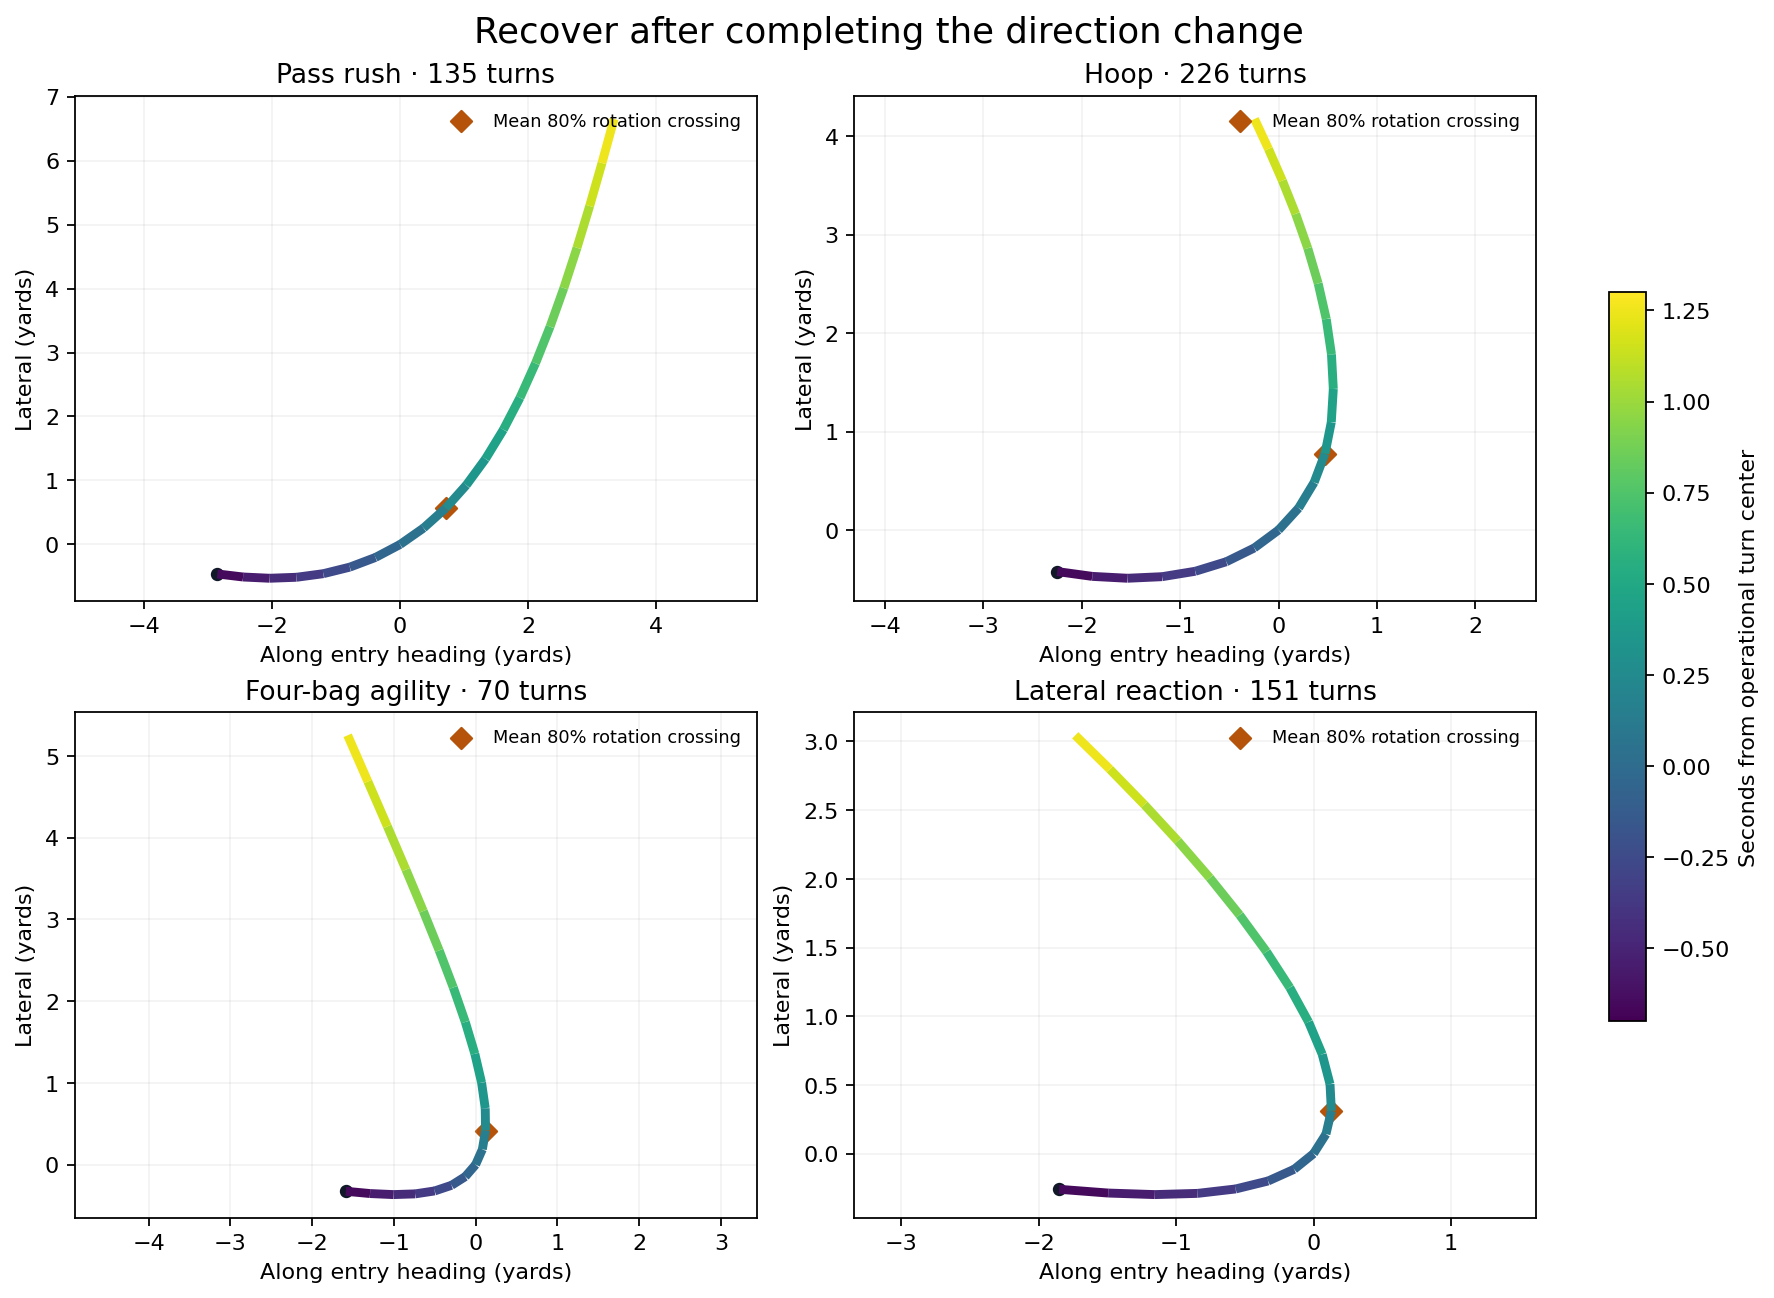

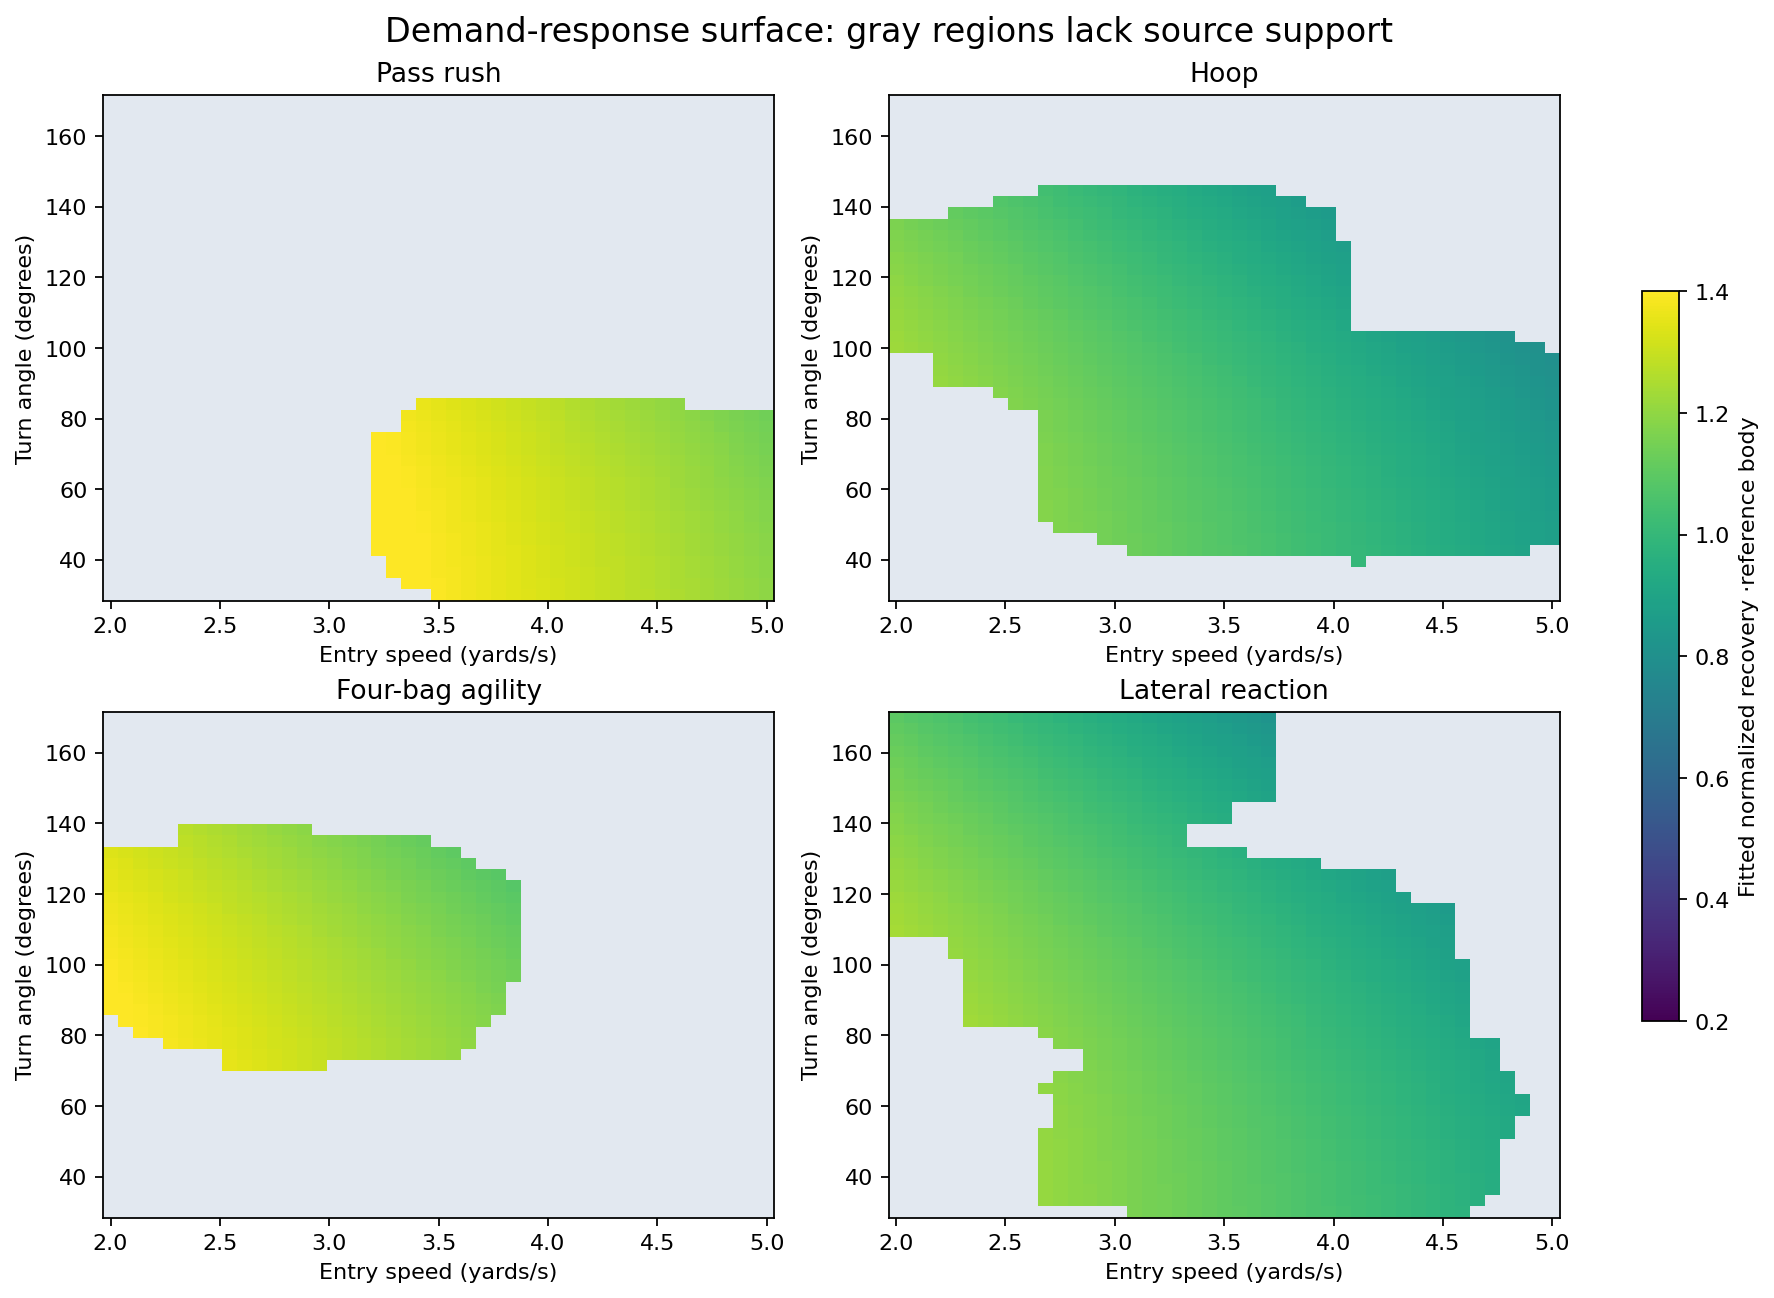

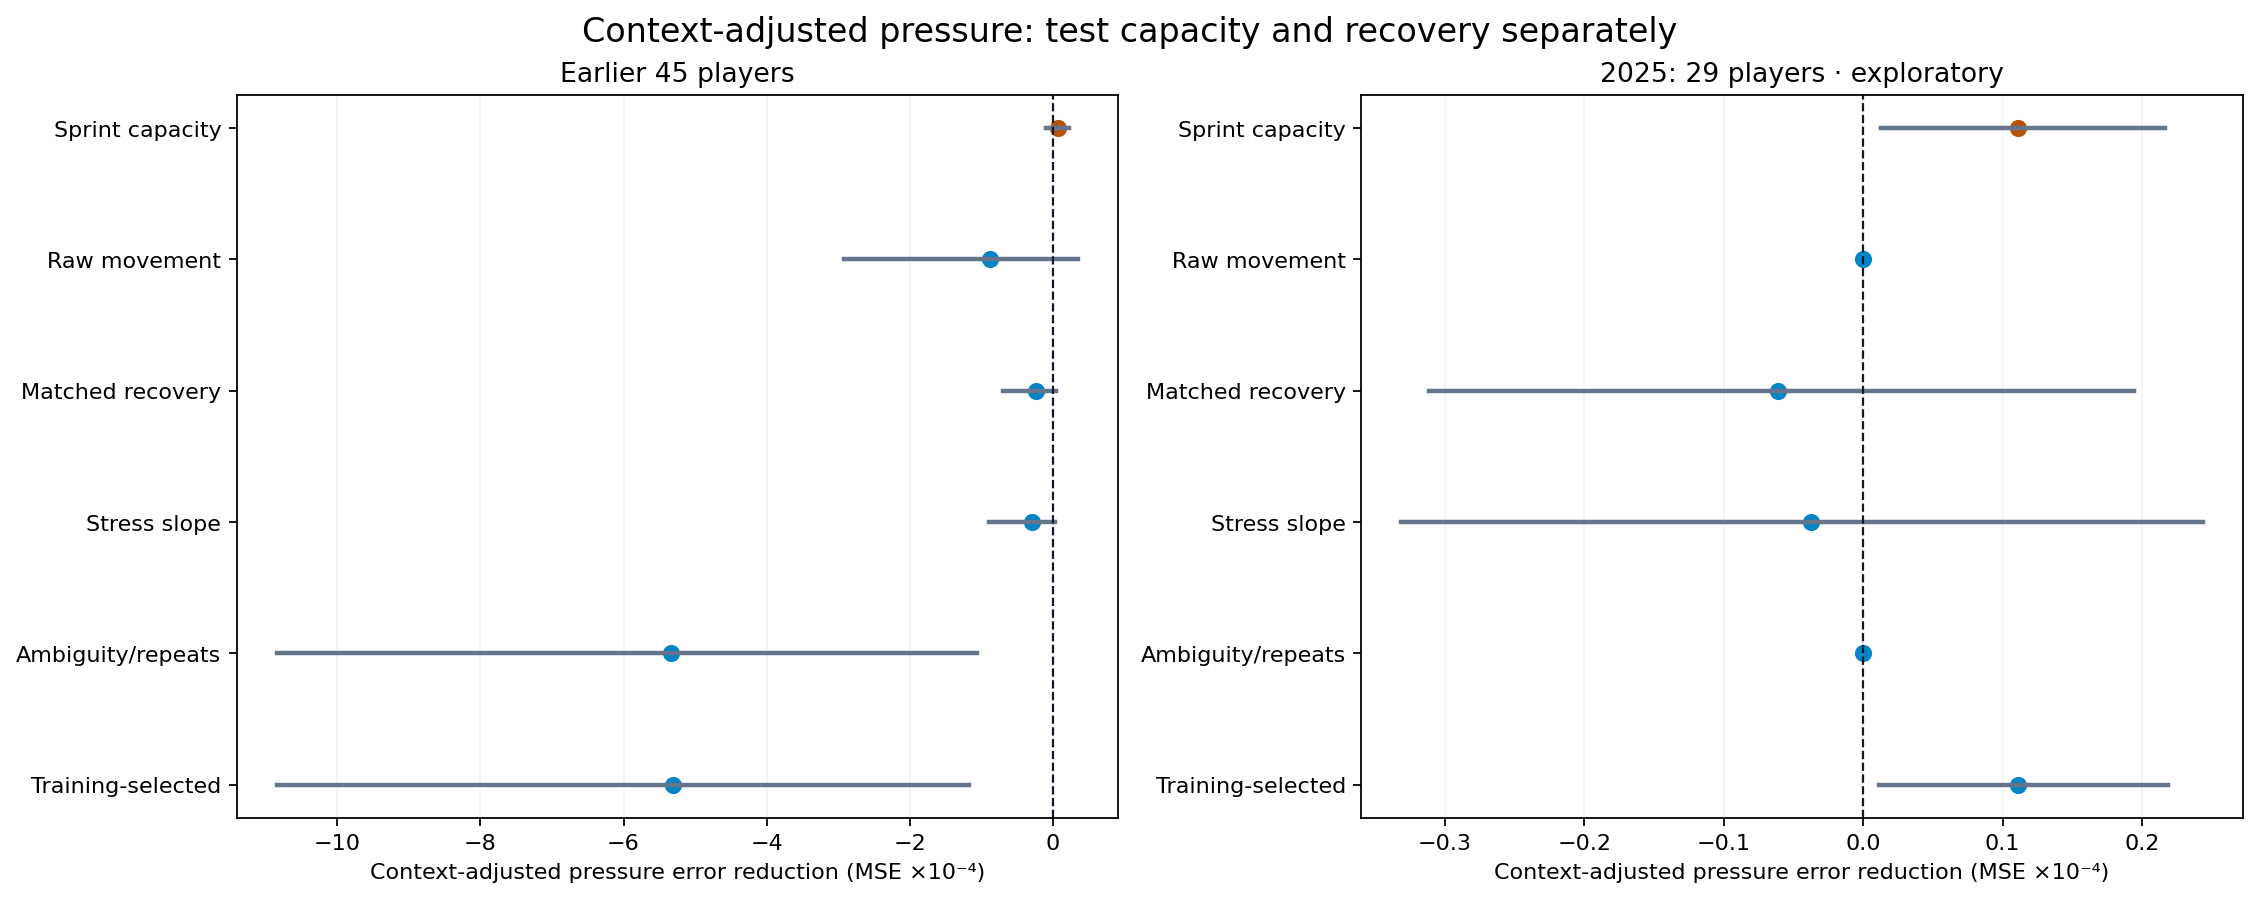

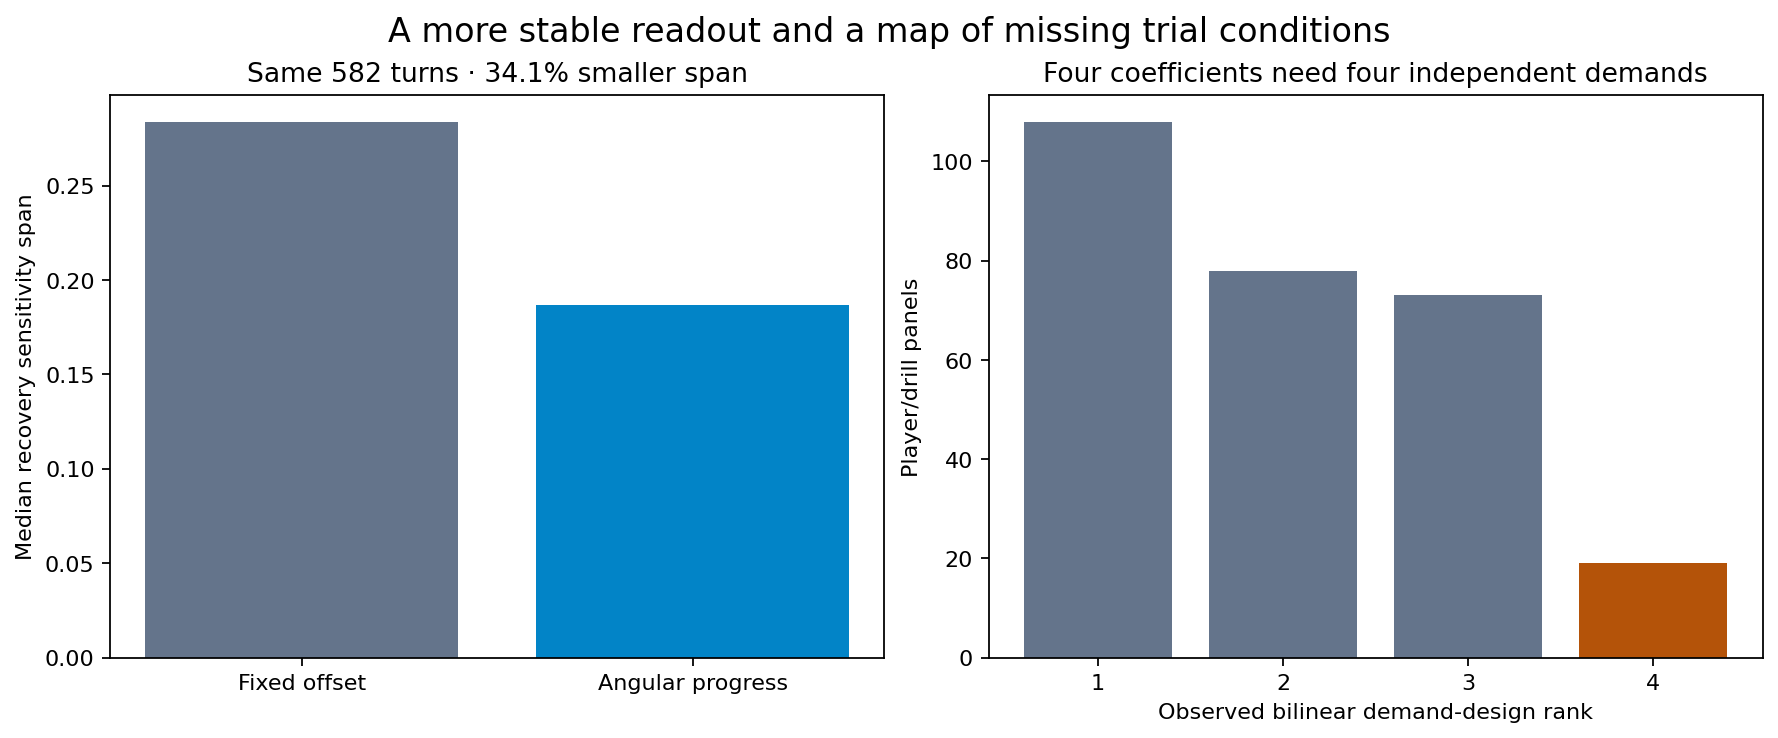

In [4]:
with (WORK/'private_stress_diagnostics.log').open('w') as log,contextlib.redirect_stdout(log):measurement,observability=D.run()
print('Matched-turn median sensitivity-span reduction:',round(measurement['median_width_reduction']*100,2),'%')
print('Repeatability:',measurement['repeatability'])
print('Player/drill design-rank counts:',observability['rank_counts'],'unidentified fraction:',observability['fraction_not_full_rank'])
with (WORK/'private_stress_refits.log').open('w') as log,contextlib.redirect_stdout(log):refits=B.run()
print('64 joint context/scout refits; interval:',refits['joint_training_test_ci95'])
with (WORK/'private_stress_contexts.log').open('w') as log,contextlib.redirect_stdout(log):situations=H.run()
for group,result in situations['groups'].items():
    if 'mse' in result:print('Fixed-penalty supporting situation',group,'players',result['players'],'MSE',result['mse'])
with (WORK/'private_stress_fixed.log').open('w') as log,contextlib.redirect_stdout(log):
    fixed=[J.run(seed,seed==T.SEED) for seed in [T.SEED,T.SEED+200,T.SEED+400]]
for result in fixed:print('Adaptive fixed1000 policy',result['seed'],'development MSE',result['development']['mse'])
print('Adaptive fixed1000 forward MSE',fixed[0]['exploratory_2025']['mse'])
G.render(OUT)
for name in ['recovery_geometry.png','stress_surface.png','scouting_results.png','measurement_and_observability.png']:display(Image(filename=str(OUT/name)))


The supporting situation audit fixes ridge at1000 and reports third-and-long (down3, at least5yards) and the supplied blitzing flag with at least10records/player. The flag defines a record subset but reuses the same45/29players; it is not an independent cohort or a causal team-blitz intervention. Its forced-feature fits motivated an explicitly adaptive fixed1000 audit across all families and three earlier partitions. No family is selected by its2025score; these diagnostics do not replace the primary nested-selection results or create independent confirmation.

## What a scout can take from this

Better recovery alignment is a measured improvement in robustness, not proof of greater NFL predictive value. Most individual demand curves remain underidentified; a precise-looking threshold would depend heavily on assumptions. Tracked sprint capacity offers a small exploratory pressure-calibration lead, while recovery additions fail to establish an incremental benefit and the supporting get-off result does not confirm it. Keep all trials, fallback choices and broader uncertainty.

The actionable evaluation direction is to diversify measured entry speeds and turn angles, validate turn-completion labels, and reserve independent athletes/outcomes. Minimum candidate trial plans quantify what the stated response model lacks. Causal player-development benefit and reliable hidden-talent identification require additional evidence.
